# COMP 551 Assignment 3

## Task 1: Acquire the data

In [23]:
# Install packages into the Python environment this notebook runs in (only needed once)
#%pip install torch torchvision torchinfo numpy pandas matplotlib seaborn


In [24]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader

# CNN imports
import time
from torchvision import models
from torchinfo import summary
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F


### **Step 1: Load Dataset**

In [25]:
# dataset objects: .data = all images (N, 28, 28), uint8 0-255; .targets = labels
# dataset[i] applies ToTensor -> image [1, 28, 28], float 0-1
train_dataset_raw = datasets.FashionMNIST(root='./data', train=True, download=True,
                                      transform=transforms.ToTensor())
test_dataset_raw = datasets.FashionMNIST(root='./data', train=False, download=True,
                                      transform=transforms.ToTensor())

# Create transform pipeline for data augmentation in Q5
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor()
])

# data set object transformed for data augmentation in Q5
train_dataset_aug = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)

In [26]:
image, label = train_dataset_raw[0]

# assign input dimension width
I = train_dataset_raw.data.shape[1]

print(type(image))
print(image.shape)
print(image.dtype)
print(image.device)
print(f"\nTrain partition: {train_dataset_raw.data.shape} {len(train_dataset_raw)} images")
print(f"Test partition: {test_dataset_raw.data.shape} {len(test_dataset_raw)} images")
print(f'Input dimension: {I}')

<class 'torch.Tensor'>
torch.Size([1, 28, 28])
torch.float32
cpu

Train partition: torch.Size([60000, 28, 28]) 60000 images
Test partition: torch.Size([10000, 28, 28]) 10000 images
Input dimension: 28


### **Step 2: Split Training Partition**

In [27]:
""" Split the default training partition (60k images)
into training and validation partitions """

from torch.utils.data import Subset

split_ratio = 0.8
split_point = int(split_ratio * len(train_dataset_raw))

rng = np.random.default_rng(2026)
indices = np.arange(len(train_dataset_raw))
rng.shuffle(indices)
train_indices = indices[:split_point]
val_indices = indices[split_point:]

train_set = Subset(train_dataset_raw, train_indices)
val_set   = Subset(train_dataset_raw, val_indices)

print(f"Train size: {len(train_set)}")
print(f"Validation size: {len(val_set)}")

Train size: 48000
Validation size: 12000


### **Step 3: Flatten Dataset**

In [28]:
# bring subsets into numpy (raw images)
X_train = train_dataset_raw.data.numpy()[train_indices]
X_val   = train_dataset_raw.data.numpy()[val_indices]
X_test  = test_dataset_raw.data.numpy()

# make a subset of augmented images that are fetched by image
train_set_aug = Subset(train_dataset_aug, train_indices)
train_loader_aug = DataLoader(train_set_aug, batch_size=len(train_set_aug), shuffle=False)

#run through train_loader and perform transforms
torch.manual_seed(2026)
xb, yb = next(iter(train_loader_aug))
xb = xb.numpy()


print(f'X_train: {X_train.shape}')
print(f'X_train_aug: {xb.shape}')
print(f'X_val: {X_val.shape}')
print(f'X_test: {X_test.shape}')

# labels
y_train = train_dataset_raw.targets.numpy()[train_indices]
y_val   = train_dataset_raw.targets.numpy()[val_indices]
y_test  = test_dataset_raw.targets.numpy()

# flatten [vectorize 28*28 = 784]
x_train = X_train.reshape(-1, 784).astype(np.float32) # convert to float
x_train_aug = xb.reshape(-1, 784).astype(np.float32)*255 # scale from 0 to 1 --> 0 to 255
x_val = X_val.reshape(-1, 784).astype(np.float32)
x_test = X_test.reshape(-1, 784).astype(np.float32)

print(f'\nx_train: dtype {x_train.dtype}, min {x_train.min():.3f}, max {x_train.max():.3f}, mean {x_train.mean():.3f}')
print(f'x_train_aug: dtype {x_train_aug.dtype}, min {x_train_aug.min():.3f}, max {x_train_aug.max():.3f}, mean {x_train_aug.mean():.3f}')

print(f'\nCheck Flattened Shape:')
print(f'x_train: {x_train.shape}')
print(f'x_train_aug: {x_train_aug.shape}')
print(f'x_val: {x_val.shape}')
print(f'x_test: {x_test.shape}')

# keep unnormalized copies for Q4
x_train_raw, x_val_raw, x_test_raw = x_train.copy(), x_val.copy(), x_test.copy()
x_train_aug_raw = x_train_aug.copy()


X_train: (48000, 28, 28)
X_train_aug: (48000, 1, 28, 28)
X_val: (12000, 28, 28)
X_test: (10000, 28, 28)

x_train: dtype float32, min 0.000, max 255.000, mean 72.877
x_train_aug: dtype float32, min 0.000, max 255.000, mean 73.103

Check Flattened Shape:
x_train: (48000, 784)
x_train_aug: (48000, 784)
x_val: (12000, 784)
x_test: (10000, 784)


### **Step 4: Normalize Dataset**

In [29]:
# normalization statistics from the training split only (not validation)
# this method based on numpy simplicity in the CS231n data processing reference

mean = x_train_raw.mean()
std = x_train_raw.std()
print(f'train mean: {mean:.3f}, train std: {std:.3f}')

# apply the same mean and std to all three sets
x_train = (x_train_raw - mean) / std
x_train_aug = (x_train_aug_raw - mean) / std
x_val   = (x_val_raw - mean) / std
x_test  = (x_test_raw - mean) / std

print(f'\ntrain: mean {x_train.mean():.3f}, std {x_train.std():.3f}')
print(f'train (augmented): mean{x_train_aug.mean():.3f}, std {x_train_aug.std():.3f}')
print(f'val:   mean {x_val.mean():.3f}, std {x_val.std():.3f}')
print(f'test:  mean {x_test.mean():.3f}, std {x_test.std():.3f}')


train mean: 72.877, train std: 90.006

train: mean -0.000, std 1.000
train (augmented): mean0.003, std 0.981
val:   mean 0.003, std 1.001
test:  mean 0.003, std 0.999


In [30]:
# Concatenate clean + augmented data set for Q5
x_train_augExpand = np.concatenate((x_train, x_train_aug), axis=0)
y_train_augExpand = np.concatenate((y_train, y_train), axis=0)

print(f'x_train_augExpand: {x_train_augExpand.shape}')
print(f'y_train_augExpand: {y_train_augExpand.shape}')

x_train_augExpand: (96000, 784)
y_train_augExpand: (96000,)


Data augmentation is most helpful to increase instances of x for expanding a dataset in order to improve regularization and help with overfitting -- so I used that to expand the data set from 48k to 96k by concatenating with the clean base and expanding the total data set.

### **Step 5: Exploratory Data Analysis**

In [31]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

#### 1. Dataset structure

In [32]:
for root, dirs, files in os.walk('./data/FashionMNIST'):

    level = root.replace('./data/FashionMNIST', "").count(os.sep)

    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:]:
        print(f"{indent}    {file}")

print(train_dataset_raw)
print("Images shape:", train_dataset_raw.data.shape)
print("Labels shape:", train_dataset_raw.targets.shape)
class_names = train_dataset_raw.classes

print("Number of classes:", len(class_names))
for class_id, class_name in enumerate(class_names):
    print(class_id, class_name)


FashionMNIST/
    raw/
        t10k-images-idx3-ubyte
        t10k-labels-idx1-ubyte
        train-images-idx3-ubyte
        t10k-images-idx3-ubyte.gz
        train-images-idx3-ubyte.gz
        train-labels-idx1-ubyte.gz
        train-labels-idx1-ubyte
        t10k-labels-idx1-ubyte.gz
Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: ToTensor()
Images shape: torch.Size([60000, 28, 28])
Labels shape: torch.Size([60000])
Number of classes: 10
0 T-shirt/top
1 Trouser
2 Pullover
3 Dress
4 Coat
5 Sandal
6 Shirt
7 Sneaker
8 Bag
9 Ankle boot


#### 2. Class Distribution - images per category

         Class  Train  Validation  Test  Total
0  T-shirt/top   4755        1245  1000   7000
1      Trouser   4852        1148  1000   7000
2     Pullover   4803        1197  1000   7000
3        Dress   4810        1190  1000   7000
4         Coat   4775        1225  1000   7000
5       Sandal   4819        1181  1000   7000
6        Shirt   4791        1209  1000   7000
7      Sneaker   4765        1235  1000   7000
8          Bag   4834        1166  1000   7000
9   Ankle boot   4796        1204  1000   7000


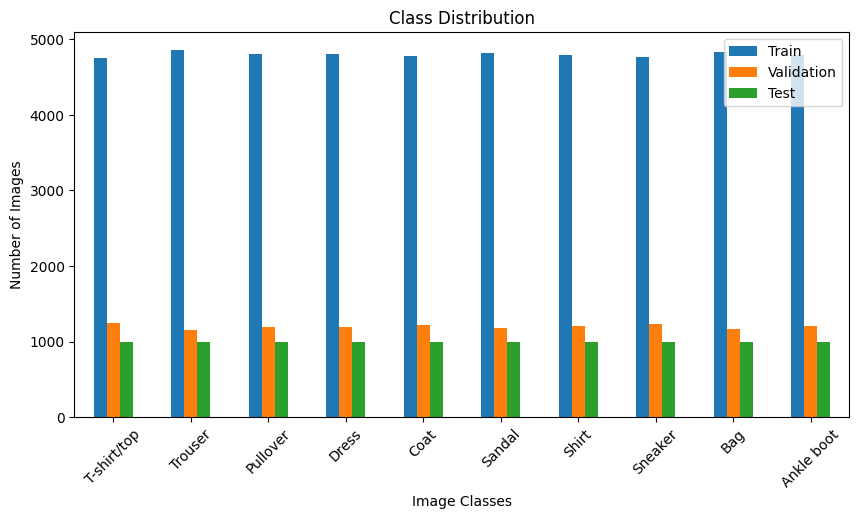

In [33]:
class_names = train_dataset_raw.classes

splits = {
    "Train": y_train,
    "Validation": y_val,
    "Test": y_test
}

class_counts = {"Class": class_names}

for split_name, labels in splits.items():
    class_counts[split_name] = np.bincount(labels, minlength=10)

class_df = pd.DataFrame(class_counts)
class_df["Total"] = class_df[["Train", "Validation", "Test"]].sum(axis=1)

print(class_df)

class_df.plot(
    kind="bar",
    x="Class",
    y=["Train", "Validation", "Test"],
    figsize=(10, 5)
)

plt.title("Class Distribution")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

#### 3. Random raw images

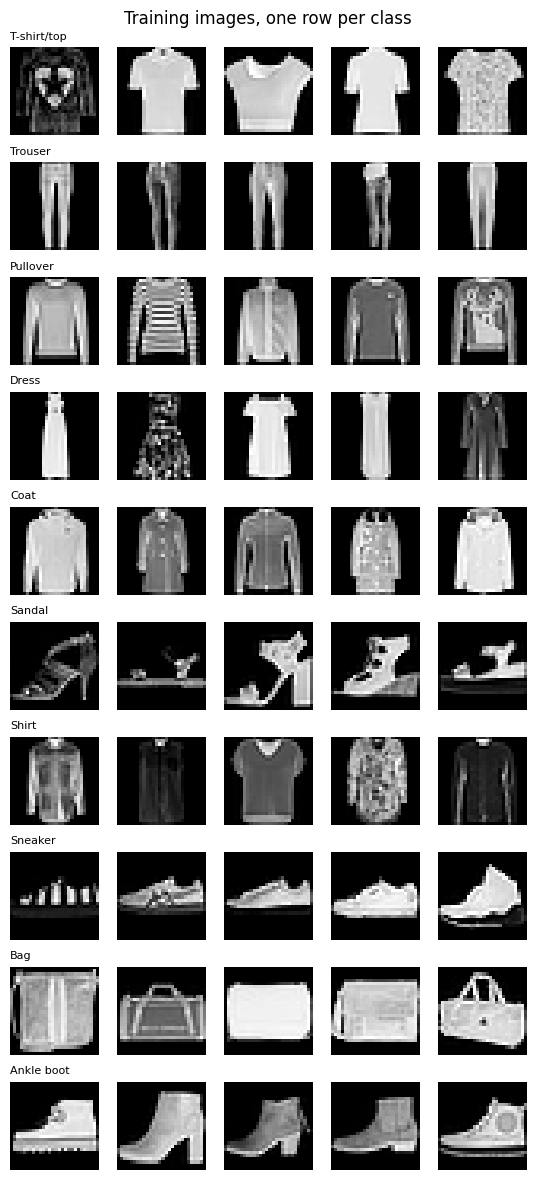

In [34]:
n_show = 5
fig, axes = plt.subplots(10, n_show, figsize=(n_show * 1.1, 10 * 1.2))
for c in range(10):
    examples = np.where(y_train == c)[0][:n_show]
    for j, i in enumerate(examples):
        axes[c, j].imshow(x_train[i].reshape(28, 28), cmap='gray')
        axes[c, j].axis('off')
    axes[c, 0].set_title(class_names[c], fontsize=8, loc='left')
plt.suptitle('Training images, one row per class')
plt.tight_layout()
plt.show()

#### 4.Pixel distribution — mean, std, intensity

raw train pixels: mean 72.88, std 90.01


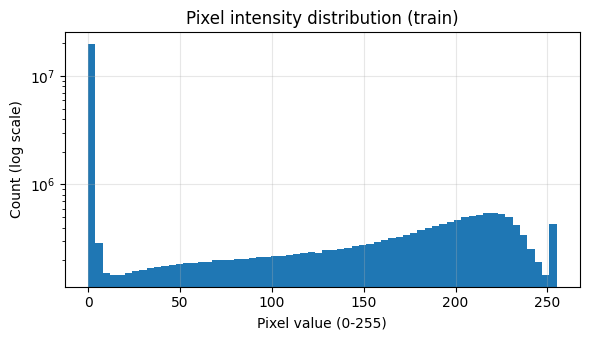

In [35]:
x_all_train = train_dataset_raw.data.numpy()
y_all_train = train_dataset_raw.targets.numpy()
x_all_test  = test_dataset_raw.data.numpy()
y_all_test  = test_dataset_raw.targets.numpy()

X_train_hist = x_all_train[train_indices]   # same split as the rest of the notebook

print(f'raw train pixels: mean {X_train_hist.mean():.2f}, std {X_train_hist.std():.2f}')

plt.figure(figsize=(6, 3.5))
plt.hist(X_train_hist.ravel(), bins=64, log=True)
plt.xlabel('Pixel value (0-255)')
plt.ylabel('Count (log scale)')
plt.title('Pixel intensity distribution (train)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### 5. Data integrity -- corrupted images


In [36]:
invalid = []
for i in range(len(train_dataset_raw)):              # reading every image like during training
    try:
        img, lable = train_dataset_raw[i]
    except Exception as e:
        invalid.append(("train", i))
for i in range(len(test_dataset_raw)):
    try:
        img, lable = test_dataset_raw[i]
    except Exception as e:
        invalid.append(('test', i))
print(f"Invalid images: {len(invalid)}")

for name, x, y in [('train partition', x_all_train, y_all_train), ('test partition', x_all_test, y_test)]:
    print(f"\n{name}:")
    print(f"  all images 28x28:        {x.shape[1:] == (28, 28)}")
    print(f"  pixel range:             [{x.min()}, {x.max()}]")
    print(f"  NaN values:              {np.isnan(x.astype(float)).sum()}")
    print(f"  labels in [0,9]:          {set(np.unique(y)) <= set(range(10))}")
    print(f"  completely blank images: {(x.reshape(len(x), -1).max(axis=1) == 0).sum()}")

Invalid images: 0

train partition:
  all images 28x28:        True
  pixel range:             [0, 255]
  NaN values:              0
  labels in [0,9]:          True
  completely blank images: 0

test partition:
  all images 28x28:        True
  pixel range:             [0, 255]
  NaN values:              0
  labels in [0,9]:          True
  completely blank images: 0


#### 6. Data leakage

In [37]:
# 6.1 image index in both training and validation
print(f"Indices shared by train and validation: {len(set(train_indices) & set(val_indices))}")

Indices shared by train and validation: 0


## Task 2: Implement a Multilayer Perceptron

Our model is an MLP with $L-1$ hidden layers and a softmax output layer:

$$
z_0 = x, \qquad
a_l = z_{l-1} W_l + b_l, \qquad
z_l = h(a_l) \quad \text{for } l = 1, \dots, L-1
$$

$$
\hat{y} = \operatorname{softmax}(a_L), \qquad a_L = z_{L-1} W_L + b_L
$$

$x$ is the flattened image (784 pixels), $h$ is the hidden activation function, $W_l$ and $b_l$ are the weights and bias for layer $l$, and $\hat{y}$ is the output probability of each of the 10 categories (softmax since it's multi-class).


An MLP is composed of three types of layers:

(1) an input layer -> flattened 784 pixels

(2) hidden layers -> every layer: $z = h(Wx+b)$ (linear transformation -> activation function)

    - Activation Function: ReLU, Tanh, Leaky-ReLU

(3) an output layer -> the probability of 10 categories $\left ( \operatorname{softmax}(u)_k = \frac{\exp(u_k)}{\sum_j \exp(u_j)} \right )$

(4)Loss:


$$L = -\frac{1}{N}\sum_{n}\sum_{k} y_{nk}\log \hat{y}_{nk}, \quad \hat{y} = \text{softmax}(a)$$

**Forward Pass:**

x --W1--> a1 --h--> z1 --W2--> a2 --h--> z2..... --Wl--> al --softmax--> yh --> L

#### Gradient

- Taking the derivative with respect to the last layer's pre-activation `a`:

$$\frac{\partial L}{\partial a} = \frac{\hat{y} - y}{N}$$

- $a = zW + b$

$$\frac{\partial L}{\partial w} = z^{T}  \frac{\partial L}{\partial a}$$
$$\frac{\partial L}{\partial z} = \frac{\partial L}{\partial a} w^{T}$$

*Chain Rule*

For $ z = h(a_{l-1})$

$$\frac{\partial L}{\partial a_{l-1}} =  h'(a_{l-1}) \odot \frac{\partial L}{\partial z}$$

- h(): activation function

Implementation should include

    - backpropagation

    - mini-batch gradient descent algorithm

- Leaky-ReLU slope γ is fixed at 0.01 here (making γ learnable would give PReLU, a possible extension)

- Weight Initialization

| Method                | Common application | Main idea                                      |
|-----------------------|--------------------|------------------------------------------------|
| Zero initialization   | Biases             | Initialize biases to zero                      |
| Random initialization | General concept    | Start weights with random values               |
| Xavier (Glorot)       | Tanh, sigmoid      | $\operatorname{Var}(W)=\frac{2}{n_{in}+n_{out}}$ |
| He (Kaiming)          | ReLU, Leaky ReLU   | $\operatorname{Var}(W)=\frac{2}{n_{in}}$         |


In [38]:
#Activation Function
relu = lambda a: np.maximum(0, a)
relu_grad = lambda a: (a > 0).astype(float)

tanh = lambda a: np.tanh(a)
tanh_grad = lambda a: 1 - np.tanh(a) ** 2

leaky_relu = lambda a: np.maximum(0, a) + 0.01 * np.minimum(0, a)
leaky_relu_grad = lambda a: np.where(a > 0, 1., 0.01)

activations = {'relu': (relu, relu_grad),
               'tanh': (tanh, tanh_grad),
               'leaky_relu': (leaky_relu, leaky_relu_grad)}

In [39]:
#The constructor for the class should take as input
# the activation function (e.g., ReLU),
# the number of hidden layers (e.g., 2)
# the number of units in the hidden layers (e.g., [64, 64])
# initialize the weights and biases (with an initializer of your choice)
# as well as other important properties of the MLP.
def one_hot(y, C):
    Y = np.zeros((len(y), C))
    Y[np.arange(len(y)), y] = 1                 # e.g. label 3 -> [0,0,0,1,0,0,0,0,0,0]
    return Y

def softmax(a):
    a = a - np.max(a, axis=1, keepdims=True)
    e = np.exp(a)
    return e / np.sum(e, axis=1, keepdims=True)

class MLP:

    def __init__(self, activation, n_hidden_layers, hidden_units, n_input , n_output, init = "default", L1 = 0, L2 = 0):
        '''
        Initialize a multilayer perceptron with a softmax output layer.

        Architecture: x -> [W1,b1] -> h -> [W2,b2] -> h -> ... -> [WL,bL] -> softmax -> yh

        Parameters:
        activation: hidden activation, 'relu', 'tanh' or 'leaky_relu'
        n_hidden_layers: number of hidden layers
        hidden_units: list with the number of units of each hidden layer
        n_input: number of input features D
        n_output: number of classes C
        init: ReLU, Leaky ReLU, Tanh or default for 0.01
        '''
        self.activation = activation
        self.n_hidden_layers = n_hidden_layers
        self.hidden_units = hidden_units
        self.h, self.h_grad = activations[activation]
        self.input_dim = n_input
        self.output_dim = n_output
        self.init = init
        self.L1 = L1
        self.L2 = L2

        self.layer_sizes = [n_input] +list(hidden_units)+[n_output]
        # Store parameters as a list for the optimizer
        self.params = [] # [W1,b1,W2,b2,...,Wl,bl]

        for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            if init == 'relu' or init == "leaky_relu":
                scale = np.sqrt(2 / n_in)
            elif init == 'tanh':
                scale = np.sqrt(2 / (n_in + n_out))
            elif init == 'default':
                scale = .01
            else:
                raise ValueError(f"Unknown init: {init}")
            W = np.random.randn(n_in, n_out) * scale  # W_{i} (n_in, n_out)
            b = np.zeros(n_out)                         # (n_out,)

            self.params.extend([W, b])

    def forward(self, x, params):
        """
        Forward pass through the network.

        Parameters:
        x: input features, shape (N, D)
        params: [W1,b1,W2,b2,...,Wl,bl]
        Returns:
        out: predicted probabilities, shape (N, 10)

        """
        L = len(params) // 2 # number of layers [W1,b1,W2,b2,...,Wl,bl]
        z = x
        h_u, p_a = [x],[]
        for l in range(L):
            W, b = params[2*l], params[2*l+1]
            a = np.dot(z, W) + b # pre-activation
            p_a.append(a)
            if l < L - 1:   # without output layer, all hidden layers go through activation function
                z = self.h(a) # after activation
                h_u.append(z)     # h_u[l] the input of l-th layer
        yh = softmax(a)

        return yh, h_u, p_a

    def gradient(self, x, y, params):
        """
        Compute gradients for both layers using backpropagation.

        Parameters:
        x: input features, shape (N, D)
        y: true labels, shape (N,)
        params: list [w1, b1... wL, bL]

        Returns:
        params: list [dw1, db1... dwL, dbL] containing gradients for W and b
        """
        N = x.shape[0]
        L = len(params) // 2
        yh, h_u, p_a = self.forward(x, params)
        # Store gradients
        dparams = [None] * len(params) #[dW1, db1, dW2, db2, ...]

        da = (yh - one_hot(y, yh.shape[1])) / N # the derivative with respect to the last layer's pre-activation

        for l in reversed(range(L)):
             W = params[2 * l]
             dW = np.dot(h_u[l].T, da)
             dW = dW + self.L1 * np.sign(W) + self.L2 * W     ## changes: regularization
             db = np.sum(da, axis=0)
             dparams[2 * l], dparams[2 * l + 1] = dW, db
             if l > 0:
                dz = np.dot(da, W.T)
                da = dz * self.h_grad(p_a[l - 1])

        return dparams


    def fit(self, x, y, optimizer):

        self.params = optimizer.run(self.gradient, x, y, self.params)
        return self

    def predict(self, x):
        yh, _, _ = self.forward(x, self.params)
        return np.argmax(yh, axis=1)

def evaluate_acc(y, yh):
    return np.mean(y == yh)



### Gradient descent (defaault batch_size config --> mini batch)

In [40]:
class GradientDescent:

    # batch_size: N = full-batch GD, 64 = mini-batch (default), 1 = SGD
    def __init__(self, learning_rate, epochs = 10, batch_size = 64):

        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size

    def run(self, gradient_fn, x, y, params):

        N = x.shape[0]
        for epoch in range(self.epochs):
            # shuffle the training data every epoch
            order = np.random.permutation(N)

            # select a batch of `batch_size` samples each time
            for i in range(0, N, self.batch_size):
                batch = order[i : i+self.batch_size]
                grad = gradient_fn(x[batch], y[batch], params)
                for p in range(len(params)):
                    params[p] -= self.learning_rate * grad[p]

            print(f"Epoch {epoch + 1}/{self.epochs} done")
        return params

In [41]:
np.random.seed(2026) # reset global RNG: same initial weights & GradientDescent shuffling, so runs are reproducible
model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
            n_input=784, n_output=10, init='relu')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model.fit(x_train, y_train, optimizer)

print(evaluate_acc(y_train, model.predict(x_train)))

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
0.9295833333333333


## Task 3: Run the experiments and report

1.
- an MLP with no hidden layers, i.e., it directly maps the inputs to outputs; (784 -> 10 -> softmax)
- an MLP with a single hidden layer having 256 units and ReLU activations; (784 -> 256 (ReLU)-> 10 -> softmax)
- an MLP with 2 hidden layers each having 256 units with ReLU activations. (784 -> 256 (ReLU) -> 256 (ReLU) ->10 -> softmax)

Have a softmax layer at the end.
After training, compare the test accuracy of these three models on the FashionMNIST dataset.
Comment on how non-linearity and network depth affects the accuracy. Are the results that you obtain expected?

### Hyperparameter selection

#### 1. Learning rate

In [42]:
# Learning-rate sweep on the 2-hidden-layer ReLU MLP (selected by VALIDATION accuracy)
lr_rows = []
for lr in [0.005, 0.01, 0.05, 0.1, 0.2]:
    np.random.seed(2026)
    model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu')
    model.fit(x_train, y_train, GradientDescent(learning_rate=lr, epochs=10, batch_size=64))
    lr_rows.append({'learning rate': lr,
                    'train acc': evaluate_acc(y_train, model.predict(x_train)),
                    'val acc':   evaluate_acc(y_val,   model.predict(x_val))})

pd.DataFrame(lr_rows).round(3)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,learning rate,train acc,val acc
0,0.005,0.886,0.873
1,0.010,0.901,0.879
2,0.050,0.930,0.888
3,0.100,0.932,0.887
4,0.200,0.932,0.888


#### 2. Batch Size

In [43]:
# Batch-size sweep
bs_rows = []
for bs in [32, 64, 128, 256]:
    np.random.seed(2026)
    model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu')
    model.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=bs))
    bs_rows.append({'batch size': bs,
                    'epoch': int(np.ceil(len(x_train) / bs)),
                    'train acc': evaluate_acc(y_train, model.predict(x_train)),
                    'val acc':   evaluate_acc(y_val,   model.predict(x_val))})

pd.DataFrame(bs_rows).round(4)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,batch size,epoch,train acc,val acc
0,32,1500,0.9406,0.8920
1,64,750,0.9296,0.8877
2,128,375,0.9195,0.8880
3,256,188,0.8958,0.8742


- leaning rate 0.05 is good
- batch size 64 is good.

### 3.1

In [44]:
# 1: MLP with no hidden layer
np.random.seed(2026)
model_0 = MLP(activation='relu', n_hidden_layers=0, hidden_units=[],
              n_input=784, n_output=10, init='relu') # keep the initial the same
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_0.fit(x_train, y_train, optimizer)

train_acc_0 = evaluate_acc(y_train, model_0.predict(x_train))
test_acc_0  = evaluate_acc(y_test,  model_0.predict(x_test))

# 2: MLP with 1 hidden layer (256 units, ReLU)
np.random.seed(2026) 
model_1 = MLP(activation='relu', n_hidden_layers=1, hidden_units=[256],
              n_input=784, n_output=10, init='relu') # keep the initial the same
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_1.fit(x_train, y_train, optimizer)

train_acc_1 = evaluate_acc(y_train, model_1.predict(x_train))
test_acc_1  = evaluate_acc(y_test,  model_1.predict(x_test))

# 3: MLP with 2 hidden layers (256 units each, ReLU)
np.random.seed(2026) 
model_2 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
              n_input=784, n_output=10, init='relu')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_2.fit(x_train, y_train, optimizer)

train_acc_2 = evaluate_acc(y_train, model_2.predict(x_train))
test_acc_2  = evaluate_acc(y_test,  model_2.predict(x_test))
# result
print(f'No hidden layer -> train accuracy: {train_acc_0:.4f}, test accuracy: {test_acc_0:.4f}')
print(f'1 hidden layer -> train accuracy: {train_acc_1:.4f}, test accuracy: {test_acc_1:.4f}')
print(f'2 hidden layers -> train accuracy: {train_acc_2:.4f}, test accuracy: {test_acc_2:.4f}')


Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
No hidden layer -> train accuracy: 0.8620, test accuracy: 0.8364
1 hidden layer -> train accuracy: 0.9290, test accuracy: 0.8823
2 hidden layers -> train accuracy: 0.9296, test accuracy: 0.8771


In [45]:
q1_table = pd.DataFrame({
    'model':     ['No hidden layer', '1 hidden layer (256)', '2 hidden layers (256, 256)'],
    'train accuracy': [train_acc_0, train_acc_1, train_acc_2],
    'test accuracy':  [test_acc_0,  test_acc_1,  test_acc_2],
})
q1_table['train - test'] = q1_table['train accuracy'] - q1_table['test accuracy']
q1_table.round(4)

# model_0 to model_1 shows the effect of non-linearity, train and test accuracy is not high, underfitting
# model_1 to model_2 shows the effect of network depth affects the accuracy

,model,train accuracy,test accuracy,train - test
0,No hidden layer,0.8620,0.8364,0.0256
1,1 hidden layer (256),0.9290,0.8823,0.0467
2,"2 hidden layers (256, 256)",0.9296,0.8771,0.0525


### 3.2

Take the one with 2 hidden layers, change activation:
1) tanh and
2) Leaky-ReLU.

After training these two models compare their test accuracies with model having ReLU activations.

Comment on the performances of these models: which one is better and why? Are certain activations better than others? If the results are not as you expected, what could be the reason?

In [46]:
# 2 hidden layers with tanh activation
np.random.seed(2026)
model_tanh = MLP(activation='tanh', n_hidden_layers=2, hidden_units=[256, 256],
                 n_input=784, n_output=10, init='tanh')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_tanh.fit(x_train, y_train, optimizer)

train_acc_tanh = evaluate_acc(y_train, model_tanh.predict(x_train))
test_acc_tanh  = evaluate_acc(y_test,  model_tanh.predict(x_test))
print(f'tanh -> train accuracy: {train_acc_tanh:.4f}, valid accuracy: {test_acc_tanh:.4f}')

# Q2-2: 2 hidden layers with Leaky-ReLU activation
np.random.seed(2026)
model_leaky = MLP(activation='leaky_relu', n_hidden_layers=2, hidden_units=[256, 256],
                  n_input=784, n_output=10, init='leaky_relu')
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_leaky.fit(x_train, y_train, optimizer)

train_acc_leaky = evaluate_acc(y_train, model_leaky.predict(x_train))
test_acc_leaky  = evaluate_acc(y_test,  model_leaky.predict(x_test))
print(f'Leaky-ReLU -> train accuracy: {train_acc_leaky:.4f}, test accuracy: {test_acc_leaky:.4f}')

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
tanh -> train accuracy: 0.9278, valid accuracy: 0.8793
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Leaky-ReLU -> train accuracy: 0.9332, test accuracy: 0.8794


In [47]:
q2_table = pd.DataFrame({
    'activation': ['ReLU', 'Tanh', 'Leaky-ReLU'],
    'train accuracy':  [train_acc_2, train_acc_tanh, train_acc_leaky],
    'test accuracy':   [test_acc_2,  test_acc_tanh,  test_acc_leaky],
})
q2_table['train - test'] = q2_table['train accuracy'] - q2_table['test accuracy']
q2_table.round(4)

,activation,train accuracy,test accuracy,train - test
0,ReLU,0.9296,0.8771,0.0525
1,Tanh,0.9278,0.8793,0.0485
2,Leaky-ReLU,0.9332,0.8794,0.0538


In [48]:
# Dead units: hidden units whose pre-activation a <= 0 for validation sample
dead_rows = []
for name, m in [('ReLU', model_2), ('Leaky-ReLU', model_leaky)]:
    _, _, p_a = m.forward(x_val, m.params)
    for l in range(2):                              # the 2 hidden layers
        a = p_a[l]
        dead_rows.append({'activation': name,
                          'layer': l + 1,
                          'dead units': np.mean(np.all(a <= 0, axis=0))})

pd.DataFrame(dead_rows)

,activation,layer,dead units
0,ReLU,1,0.0
1,ReLU,2,0.0
2,Leaky-ReLU,1,0.0
3,Leaky-ReLU,2,0.0


In [49]:
# Repeat with 5 seeds to check
seed_rows = []
for act in ['relu', 'tanh', 'leaky_relu']:
    for seed in [2024, 2025, 2026, 2027, 2028]:
        np.random.seed(seed)
        m = MLP(activation=act, n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init=act)
        m.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
        seed_rows.append({'activation': act, 'seed': seed,
                          'train accuracy': evaluate_acc(y_train, m.predict(x_train)),
                          'test accuracy':  evaluate_acc(y_test,  m.predict(x_test))})

seed_df = pd.DataFrame(seed_rows)
seed_df.groupby('activation')[['train accuracy', 'test accuracy']].agg(['mean', 'std']).round(4)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Ep

train accuracy         test accuracy        
                     mean     std          mean     std
activation                                             
leaky_relu         0.9343  0.0023        0.8793  0.0016
relu               0.9344  0.0036        0.8792  0.0026
tanh               0.9259  0.0030        0.8789  0.0022

### 3.3

independently add L1 and L2 regularization to the network and train the MLP in this way.
- $$\text{L1:}\quad J = L + \lambda_1 \sum |W| \qquad \text{L2:}\quad J = L + \frac{\lambda_2}{2} \sum W^2$$
- $$\qquad \frac{\partial J}{\partial W} = \frac{\partial L_{CE}}{\partial W} + \lambda_1\,\text{sign}(W) \quad \frac{\partial J}{\partial W} = \frac{\partial L_{CE}}{\partial W} + \lambda_2 W$$

In [50]:
L1_rows = []
for lam in [0, 1e-6, 1e-5, 1e-4, 1e-3]:
    np.random.seed(2026)
    model_l1 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L1=lam)
    model_l1.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
    L1_rows.append({'lambda_1': lam,
                    'train accuracy': evaluate_acc(y_train, model_l1.predict(x_train)),
                    'val accuracy':   evaluate_acc(y_val,   model_l1.predict(x_val)),
                    'test accuracy':  evaluate_acc(y_test,  model_l1.predict(x_test))})

pd.DataFrame(L1_rows).round(6)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,lambda_1,train accuracy,val accuracy,test accuracy
0,0.000000,0.929583,0.887667,0.8771
1,0.000001,0.931438,0.891333,0.8807
2,0.000010,0.931250,0.892250,0.8783
3,0.000100,0.910833,0.886917,0.8732
4,0.001000,0.853500,0.849083,0.8403


λ1=0.000010 val accuracy is highest -- L1 regularization help

In [51]:
L2_rows = []
for lam in [0, 1e-6, 1e-5, 1e-4, 1e-3]:
    np.random.seed(2026)
    model_l2 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L2=lam)
    model_l2.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
    L2_rows.append({'lambda_2': lam,
                    'train accuracy': evaluate_acc(y_train, model_l2.predict(x_train)),
                    'val accuracy':   evaluate_acc(y_val,   model_l2.predict(x_val)),
                    'test accuracy':  evaluate_acc(y_test,  model_l2.predict(x_test))})

pd.DataFrame(L2_rows).round(6)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,lambda_2,train accuracy,val accuracy,test accuracy
0,0.000000,0.929583,0.887667,0.8771
1,0.000001,0.931750,0.889917,0.8788
2,0.000010,0.930875,0.892000,0.8776
3,0.000100,0.931188,0.890083,0.8788
4,0.001000,0.922333,0.891750,0.8785


λ2=0.000010 regularization helped but nominally +0.0039 accuracy

### 3.4

In [52]:
# Q4: trained on unnormalized pixels
np.random.seed(2026)
model_raw = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu')
model_raw.fit(x_train_raw, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))

print(f'train accuracy: {evaluate_acc(y_train, model_raw.predict(x_train_raw)):.4f}')
print(f'validation accuracy:   {evaluate_acc(y_val,   model_raw.predict(x_val_raw)):.4f}')
print(f'test accuracy:  {evaluate_acc(y_test,  model_raw.predict(x_test_raw)):.4f}')

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
train accuracy: 0.1001
validation accuracy:   0.0998
test accuracy:  0.1000


In [53]:
# Check the weights and the dead units after training
_, _, p_a = model_raw.forward(x_val_raw, model_raw.params)
print(f'max |W1|: {np.abs(model_raw.params[0]).max():.3g}')
print(f'dead units in layer 1: {np.mean(np.all(p_a[0] <= 0, axis=0)):.4f}')
print(f'max |W2|: {np.abs(model_raw.params[2]).max():.3g}')
print(f'dead units in layer 2: {np.mean(np.all(p_a[1] <= 0, axis=0)):.4f}')


max |W1|: 1.1e+14
dead units in layer 1: 0.9922
max |W2|: 6.6e+20
dead units in layer 2: 0.9844


In [54]:
# Is it only the learning rate? Re-tune lr for raw inputs (selected by validation)
raw_rows = []
for lr in [1e-3, 5e-4, 1e-4, 5e-5, 1e-5]:
    np.random.seed(2026)
    model = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu')
    model.fit(x_train_raw, y_train, GradientDescent(learning_rate=lr, epochs=10, batch_size=64))
    raw_rows.append({'learning rate': lr,
                     'train acc': evaluate_acc(y_train, model.predict(x_train_raw)),
                     'val acc':   evaluate_acc(y_val,   model.predict(x_val_raw))})

pd.DataFrame(raw_rows).round(6)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,learning rate,train acc,val acc
0,0.00100,0.709542,0.701500
1,0.00050,0.849375,0.819000
2,0.00010,0.843167,0.817417
3,0.00005,0.835021,0.812667
4,0.00001,0.794458,0.785750


In [55]:
width_rows = []
for w in [32, 64, 128, 256, 512]:
    np.random.seed(2026)
    model_width = MLP(activation='relu', n_hidden_layers=2, hidden_units=[w, w],
                n_input=784, n_output=10, init='relu')
    t0 = time.time()
    model_width.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
    train_time = time.time() - t0          # only training time, not evaluation
    width_rows.append({'width': w,
                       'train accuracy': evaluate_acc(y_train, model_width.predict(x_train)),
                       'val accuracy':   evaluate_acc(y_val,   model_width.predict(x_val)),
                       'test accuracy':  evaluate_acc(y_test,  model_width.predict(x_test)),
                       'time (s)':       train_time})

pd.DataFrame(width_rows).round(4)


Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,width,train accuracy,val accuracy,test accuracy,time (s)
0,32,0.8899,0.8677,0.8596,1.5286
1,64,0.9141,0.8787,0.8745,2.7303
2,128,0.9248,0.8882,0.8780,5.9532
3,256,0.9296,0.8877,0.8771,13.6040
4,512,0.9490,0.8921,0.8862,43.1268


In [84]:
def train_with_history(model, x_tr, y_tr, x_te, y_te, lr=0.05, epochs=10, bs=64):
    """Train one epoch at a time and record train/test accuracy after each epoch."""
    hist = {'train': [], 'test': [], 'time': 0.0}
    for ep in range(epochs):
        t0 = time.time()
        model.fit(x_tr, y_tr, GradientDescent(learning_rate=lr, epochs=1, batch_size=bs))
        hist['time'] += time.time() - t0          # only count training time, not evaluation
        hist['train'].append(evaluate_acc(y_tr, model.predict(x_tr)))
        hist['test'].append(evaluate_acc(y_te, model.predict(x_te)))
    return hist

def plot_curves(curves, title, ax):
    """curves = {label: (train_acc_list, test_acc_list)}; solid = test, dashed = train"""
    for i, (name, (tr, te)) in enumerate(curves.items()):
        c = plt.cm.tab10(i)
        ep = np.arange(1, len(te) + 1)
        ax.plot(ep, te, '-o', ms=4, lw=2, color=c, label=name)
        ax.plot(ep, tr, '--', lw=1.5, color=c, alpha=0.6)
    ax.set(title=title, xlabel='Epoch', ylabel='Accuracy')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, title='solid = test, dashed = train', title_fontsize=8)

### 3.5

*Retrain the MLP from Q3 on a version of FashionMNIST using data augmentation.*

In [56]:
# Q5: Retrain MLP Q3 (2 layer, 256 units, ReLU activation, l2 = 0.0001) on augmented data

import time

np.random.seed(2026)
# L2 from Q3 optimization
model_aug = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L2=0.0001)
optimizer = GradientDescent(learning_rate=0.05, epochs=10, batch_size=64)
model_aug.fit(x_train_augExpand, y_train_augExpand, optimizer)

train_acc_aug = evaluate_acc(y_train_augExpand, model_aug.predict(x_train_augExpand))
val_acc_aug   = evaluate_acc(y_val,   model_aug.predict(x_val))
test_acc_aug  = evaluate_acc(y_test,  model_aug.predict(x_test))

# Q3 model: clean data - time comparison
np.random.seed(2026)
model_q3 = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
               n_input=784, n_output=10, init='relu', L2=0.0001)
t0 = time.time()
model_q3.fit(x_train, y_train, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
time_q3 = time.time() - t0

# Q5 model: clean + augmented data - time comparison
np.random.seed(2026)
model_aug = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L2=0.0001)
t0 = time.time()
model_aug.fit(x_train_augExpand, y_train_augExpand, GradientDescent(learning_rate=0.05, epochs=10, batch_size=64))
time_aug = time.time() - t0

#results
q3_l2 = pd.DataFrame(L2_rows)
q3 = q3_l2[q3_l2['lambda_2'] == 1e-4].iloc[0]

pd.DataFrame([
    {'model': 'Q3: L2=0.0001, clean data',
     'train data size': len(x_train),
     'train acc': evaluate_acc(y_train, model_q3.predict(x_train)),
     'val acc':   evaluate_acc(y_val,   model_q3.predict(x_val)),
     'test acc':  evaluate_acc(y_test,  model_q3.predict(x_test)),
     'train time (s)': time_q3},
    {'model': 'Q5: L2=0.0001, clean + augmented',
     'train data size': len(x_train_augExpand),
     'train acc': evaluate_acc(y_train_augExpand, model_aug.predict(x_train_augExpand)),
     'val acc':   evaluate_acc(y_val,   model_aug.predict(x_val)),
     'test acc':  evaluate_acc(y_test,  model_aug.predict(x_test)),
     'train time (s)': time_aug},
]).set_index('model').round(4)

Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done
Epoch 1/10 done
Epoch 2/10 done
Epoch 3/10 done
Epoch 4/10 done
Epoch 5/10 done
Epoch 6/10 done
Epoch 7/10 done
Epoch 8/10 done
Epoch 9/10 done
Epoch 10/10 done


,train data size,train acc,val acc,test acc,train time (s)
model,,,,,
"Q3: L2=0.0001, clean data",48000,0.9312,0.8901,0.8788,14.2559
"Q5: L2=0.0001, clean + augmented",96000,0.9282,0.8890,0.8789,27.2956


Augmenting the data doesn't improve validation accuracy for the L2 regularized MLP from Q3. This makes sense because L2 regularization also showed the model was not very overfit, so it had little to gain.

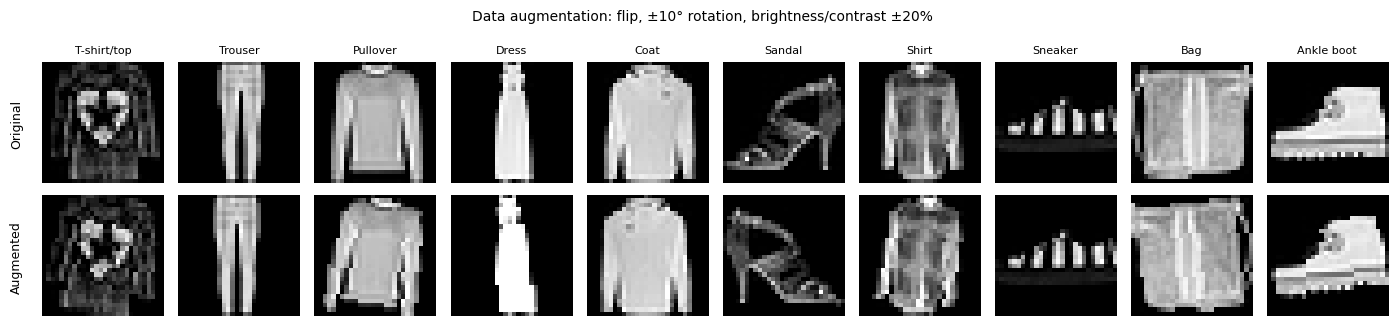

In [57]:
# Q5: original vs augmented examples, one per class
fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for c in range(10):
    i = np.where(y_train == c)[0][0]          # first training image of class c
    axes[0, c].imshow(X_train[i], cmap='gray')
    axes[1, c].imshow(xb[i, 0], cmap='gray')  # same image after augmentation
    axes[0, c].set_title(class_names[c], fontsize=8)
    axes[0, c].axis('off')
    axes[1, c].axis('off')

axes[0, 0].text(-8, 14, 'Original',  rotation=90, va='center', fontsize=9)
axes[1, 0].text(-8, 14, 'Augmented', rotation=90, va='center', fontsize=9)
plt.suptitle('Data augmentation: flip, ±10° rotation, brightness/contrast ±20%', fontsize=10)
plt.tight_layout()
plt.show()

Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
Epoch 1/1 done
clean final test acc: 0.8788  vs Q5 cell: 0.8788
aug   final test acc: 0.8789  vs Q5 cell: 0.8789


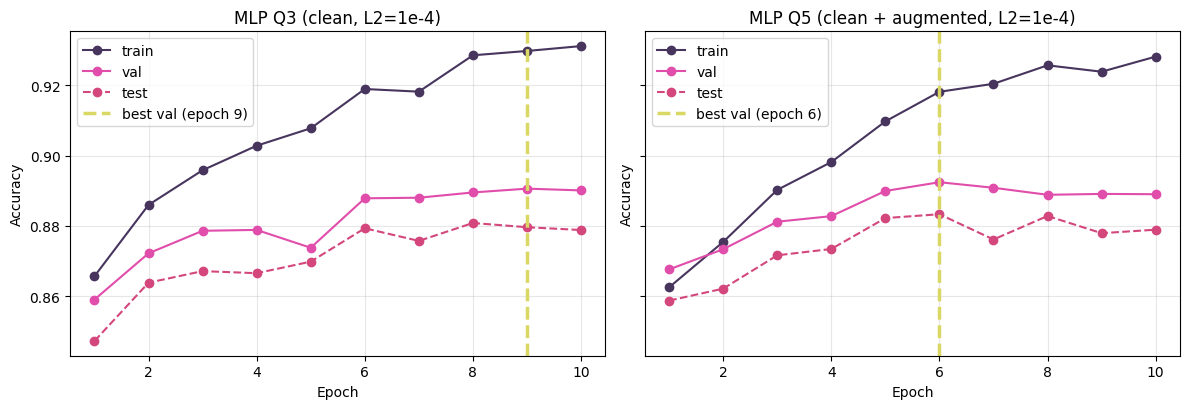

In [58]:
# [SUGGESTED ADDITION - commented out] Q10: MLP train / val / test accuracy vs. epoch.
# Original MLP / GradientDescent code is untouched: fit() is called with epochs=1, 10 times.
# To use: uncomment all lines (Cmd + /) and run after the Q5 cell (needs model_q3, model_aug).

# Q5 / Q10: train 1 epoch per fit() call, loop 10 times, record train / val / test accuracy after each epoch
n_epochs = 10

# MLP Q3 (L2=1e-4) on clean data
np.random.seed(2026)
mlp_clean = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
                n_input=784, n_output=10, init='relu', L2=0.0001)
opt_1epoch = GradientDescent(learning_rate=0.05, epochs=1, batch_size=64)
hist_mlp_clean = {'train': [], 'val': [], 'test': []}

for epoch in range(n_epochs):
    mlp_clean.fit(x_train, y_train, opt_1epoch)          # continues from the previous epoch's weights
    hist_mlp_clean['train'].append(evaluate_acc(y_train, mlp_clean.predict(x_train)))
    hist_mlp_clean['val'].append(evaluate_acc(y_val,   mlp_clean.predict(x_val)))
    hist_mlp_clean['test'].append(evaluate_acc(y_test,  mlp_clean.predict(x_test)))

# MLP Q5 (L2=1e-4) on clean + augmented data
np.random.seed(2026)
mlp_aug = MLP(activation='relu', n_hidden_layers=2, hidden_units=[256, 256],
              n_input=784, n_output=10, init='relu', L2=0.0001)
opt_1epoch = GradientDescent(learning_rate=0.05, epochs=1, batch_size=64)
hist_mlp_aug = {'train': [], 'val': [], 'test': []}

for epoch in range(n_epochs):
    mlp_aug.fit(x_train_augExpand, y_train_augExpand, opt_1epoch)
    hist_mlp_aug['train'].append(evaluate_acc(y_train_augExpand, mlp_aug.predict(x_train_augExpand)))
    hist_mlp_aug['val'].append(evaluate_acc(y_val,  mlp_aug.predict(x_val)))
    hist_mlp_aug['test'].append(evaluate_acc(y_test, mlp_aug.predict(x_test)))

# sanity check: should match model_q3 / model_aug from the Q5 cell above exactly
print(f"clean final test acc: {hist_mlp_clean['test'][-1]:.4f}  vs Q5 cell: {evaluate_acc(y_test, model_q3.predict(x_test)):.4f}")
print(f"aug   final test acc: {hist_mlp_aug['test'][-1]:.4f}  vs Q5 cell: {evaluate_acc(y_test, model_aug.predict(x_test)):.4f}")

# plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (title, hist) in zip(axes, [('MLP Q3 (clean, L2=1e-4)', hist_mlp_clean),
                                    ('MLP Q5 (clean + augmented, L2=1e-4)', hist_mlp_aug)]):
    ep = range(1, len(hist['train']) + 1)
    best = int(np.argmax(hist['val'])) + 1
    ax.plot(ep, hist['train'], color='#47355E', marker='o', label='train')
    ax.plot(ep, hist['val'],   color='#E04DAA', marker='o', label='val')
    ax.plot(ep, hist['test'],  color='#D3477D', marker='o', linestyle='--', label='test')
    ax.axvline(best, color='#DAD865', linewidth=2.5, linestyle='--', label=f'best val (epoch {best})')
    ax.set(title=title, xlabel='Epoch', ylabel='Accuracy')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 3.6

*Create a CNN class*

In [59]:
# Q6 create CNN with 2 convolutional layers, one fully connected (FC) hidden and one output

# Check if GPU is available
# Default to CPU but provide the option to use GPU
device = torch.device('cuda' if torch.cuda.is_available()          
                      else 'mps' if torch.backends.mps.is_available()  # Local Apple Silicon GPU bc Google SUCKS
                      else 'cpu')
print(f'Using device: {device}')

class ConvNet(nn.Module): # create a convolutional neural network CNN
  """ Architecture: 2 conv layers + 2 FC layers
  Input: grey scale (1 channel) images for N batch sizes: (N, 1, 28, 28)
  Output: 10 FashionMNIST clothing classes """


  def __init__(self, in_channels=1, out_channels1=16, out_channels2=32, kernel_size=3,
               stride=1, padding=1, fc_units=256, n_classes=10, I=28, use_bn=False):

    super(ConvNet, self).__init__()

    self.conv1 = nn.Conv2d(in_channels, out_channels1, kernel_size, stride, padding)
    self.conv2 = nn.Conv2d(out_channels1, out_channels2, kernel_size, stride, padding)
    self.bn1 = nn.BatchNorm2d(out_channels1) if use_bn else nn.Identity() # batch normalization / channel
    self.bn2 = nn.BatchNorm2d(out_channels2) if use_bn else nn.Identity() # batch normalization / channel
    self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
    self.flatten = nn.Flatten()

    # run a blank image to get spatial dimensions
    with torch.no_grad():
      x = torch.zeros(1, in_channels, I, I)
      x = self.pool(F.relu(self.conv1(x)))
      x = self.pool(F.relu(self.conv2(x)))
      _, c, h, w = x.shape

    self.fc1 = nn.Linear(c * h * w, fc_units)
    self.fc2 = nn.Linear(fc_units, n_classes)


  def forward(self, x): #forward pass in the network

  # convolutional block 1
    x = self.conv1(x)
    x = self.bn1(x)
    x = F.relu(x)
    x = self.pool(x)

  # convolutional block 2
    x = self.conv2(x)
    x = self.bn2(x)
    x = F.relu(x)
    x = self.pool(x)

  # flatten spatial dimensions
    x = self.flatten(x)

  # first fully connected layer with ReLU
    x = self.fc1(x)
    x = F.relu(x)

  # second fully connected layer
    x = self.fc2(x)

    return x



Using device: mps


*Initiate the model*

In [60]:
# Initiate the model and move to device (CPU or GPU)
model1 = ConvNet(out_channels1=16, out_channels2=32, kernel_size=3, stride=1, padding=1, fc_units=256, I=I).to(device)
summary(model1, input_size=(1, 1, I, I))

Layer (type:depth-idx)                   Output Shape              Param #
ConvNet                                  [1, 10]                   --
├─Conv2d: 1-1                            [1, 16, 28, 28]           160
├─Identity: 1-2                          [1, 16, 28, 28]           --
├─MaxPool2d: 1-3                         [1, 16, 14, 14]           --
├─Conv2d: 1-4                            [1, 32, 14, 14]           4,640
├─Identity: 1-5                          [1, 32, 14, 14]           --
├─MaxPool2d: 1-6                         [1, 32, 7, 7]             --
├─Flatten: 1-7                           [1, 1568]                 --
├─Linear: 1-8                            [1, 256]                  401,664
├─Linear: 1-9                            [1, 10]                   2,570
Total params: 409,034
Trainable params: 409,034
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 1.44
Input size (MB): 0.00
Forward/backward pass size (MB): 0.15
Params size (MB): 1.64
Estimated Total Si

*process data for CNN specifically*

In [61]:
# reshape data as tensors in memory for CNN
from torch.utils.data import TensorDataset

def make_loader(x, y, shuffle, batch_size=64):
    X = torch.from_numpy(x).float().reshape(-1, 1, 28, 28)
    Y = torch.from_numpy(y).long()
    return DataLoader(TensorDataset(X, Y), batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(x_train, y_train, shuffle=True)
val_loader   = make_loader(x_val,   y_val,   shuffle=False)
test_loader  = make_loader(x_test,  y_test,  shuffle=False)


*Train the model*

In [62]:

# Define hyperparameters
epochs = 10     # validation loss bottoms at epoch 9
lr = 0.01       # from sweep
momentum = 0.9  # from sweep

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():  # no gradients needed for evaluation: saves memory and time
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

# Train the model
def train_model(model, train_loader, val_loader, test_loader, epochs, lr, momentum):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    history = {'train_loss': [], 'val_loss': [], 'test_loss': [],
               'train_acc': [], 'val_acc': [], 'test_acc': [], 'epoch_time': []}

    print('Starting training...')
    print(f'Training batches per epoch: {len(train_loader)}')
    print(f'Validation batches: {len(val_loader)}')

    # Gradients ON
    for epoch in range(epochs):
        model.train()
        t0 = time.time()
        running_loss = 0.0

        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)  # Shape: (batch, channel, h, w), (batch,)
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)  # Shape: (batch_size, classes)
            loss = criterion(outputs, labels)

            # Backward pass
            loss.backward()
            optimizer.step()

            # Print progress every 100 batches
            running_loss += loss.item()
            if i % 100 == 99:
                print(f'  Epoch {epoch+1}, batch {i+1}/{len(train_loader)}, loss {running_loss / 100:.4f}')
                running_loss = 0.0

        # Once per epoch, after all batches
        history['epoch_time'].append(time.time() - t0)

        train_loss, train_acc = evaluate(model, train_loader, criterion)
        val_loss,   val_acc   = evaluate(model, val_loader,   criterion)
        test_loss,  test_acc  = evaluate(model, test_loader,  criterion)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        print(f"Epoch {epoch+1}/{epochs} | "
              f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f} | "
              f"test acc {test_acc:.4f} | {history['epoch_time'][-1]:.1f}s")

    print('Training complete!')
    return history



*Tune hyperparameters*

In [63]:
def summarize(name, hist, n_train):
    best = int(np.argmax(hist['val_acc']))              # epoch index chosen by validation
    return {'model': name,
            'train size': n_train,
            'val acc (final)':  hist['val_acc'][-1],
            'test acc (final)': hist['test_acc'][-1],
            'best val epoch':   best + 1,
            'val acc (best)':   hist['val_acc'][best],
            'test acc (best)':  hist['test_acc'][best],
            'time / epoch (s)': np.mean(hist['epoch_time'][1:])}   # skip epoch 1 warm-up

In [64]:
# Learning rate sweep (choose on VALIDATION accuracy)
lrs = [0.001, 0.005, 0.01, 0.05]

lr_rows = []
for lr_try in lrs:
    torch.manual_seed(2026)
    model = ConvNet().to(device)
    hist = train_model(model, train_loader, val_loader, test_loader, epochs, lr=lr_try, momentum=0.9)
    lr_rows.append(summarize(f'lr={lr_try}', hist, len(x_train)))

pd.DataFrame(lr_rows).set_index('model').round(4)

Starting training...
Training batches per epoch: 750
Validation batches: 188
  Epoch 1, batch 100/750, loss 2.2055
  Epoch 1, batch 200/750, loss 1.5044
  Epoch 1, batch 300/750, loss 0.8878
  Epoch 1, batch 400/750, loss 0.7406
  Epoch 1, batch 500/750, loss 0.6734
  Epoch 1, batch 600/750, loss 0.6540
  Epoch 1, batch 700/750, loss 0.6154
Epoch 1/10 | train loss 0.5761 acc 0.7925 | val loss 0.5780 acc 0.7946 | test acc 0.7853 | 3.5s
  Epoch 2, batch 100/750, loss 0.5651
  Epoch 2, batch 200/750, loss 0.5669
  Epoch 2, batch 300/750, loss 0.5399
  Epoch 2, batch 400/750, loss 0.5162
  Epoch 2, batch 500/750, loss 0.5049
  Epoch 2, batch 600/750, loss 0.4928
  Epoch 2, batch 700/750, loss 0.4591
Epoch 2/10 | train loss 0.4893 acc 0.8127 | val loss 0.4928 acc 0.8141 | test acc 0.8016 | 1.9s
  Epoch 3, batch 100/750, loss 0.4603
  Epoch 3, batch 200/750, loss 0.4624
  Epoch 3, batch 300/750, loss 0.4447
  Epoch 3, batch 400/750, loss 0.4525
  Epoch 3, batch 500/750, loss 0.4410
  Epoch 3

,train size,val acc (final),test acc (final),best val epoch,val acc (best),test acc (best),time / epoch (s)
model,,,,,,,
lr=0.001,48000,0.8872,0.8774,10,0.8872,0.8774,1.9111
lr=0.005,48000,0.9095,0.9034,9,0.9096,0.9040,2.0387
lr=0.01,48000,0.9152,0.9119,9,0.9170,0.9148,2.0544
lr=0.05,48000,0.9028,0.9000,6,0.9077,0.9010,2.0941


lr = 0.01

In [65]:
# Momentum sweep (use tuned lr first, choose on VALIDATION accuracy)
momentums = [0, 0.5, 0.8, 0.9, 0.99]

mom_rows = []
for m in momentums:
    torch.manual_seed(2026)
    model = ConvNet().to(device)
    hist = train_model(model, train_loader, val_loader, test_loader, epochs, lr, m)
    mom_rows.append(summarize(f'momentum={m}', hist, len(x_train)))

pd.DataFrame(mom_rows).set_index('model').round(4)

Starting training...
Training batches per epoch: 750
Validation batches: 188
  Epoch 1, batch 100/750, loss 2.1547
  Epoch 1, batch 200/750, loss 1.2877
  Epoch 1, batch 300/750, loss 0.8654
  Epoch 1, batch 400/750, loss 0.7608
  Epoch 1, batch 500/750, loss 0.6875
  Epoch 1, batch 600/750, loss 0.6522
  Epoch 1, batch 700/750, loss 0.6399
Epoch 1/10 | train loss 0.5700 acc 0.7938 | val loss 0.5750 acc 0.7970 | test acc 0.7899 | 2.1s
  Epoch 2, batch 100/750, loss 0.5914
  Epoch 2, batch 200/750, loss 0.5955
  Epoch 2, batch 300/750, loss 0.5562
  Epoch 2, batch 400/750, loss 0.5249
  Epoch 2, batch 500/750, loss 0.5187
  Epoch 2, batch 600/750, loss 0.5081
  Epoch 2, batch 700/750, loss 0.4789
Epoch 2/10 | train loss 0.5888 acc 0.7705 | val loss 0.5913 acc 0.7693 | test acc 0.7671 | 1.9s
  Epoch 3, batch 100/750, loss 0.4753
  Epoch 3, batch 200/750, loss 0.4746
  Epoch 3, batch 300/750, loss 0.4616
  Epoch 3, batch 400/750, loss 0.4669
  Epoch 3, batch 500/750, loss 0.4540
  Epoch 3

,train size,val acc (final),test acc (final),best val epoch,val acc (best),test acc (best),time / epoch (s)
model,,,,,,,
momentum=0,48000,0.8734,0.8653,9,0.8893,0.8752,2.1129
momentum=0.5,48000,0.8944,0.8866,9,0.9028,0.8888,2.0739
momentum=0.8,48000,0.9037,0.8982,9,0.9151,0.9055,2.1859
momentum=0.9,48000,0.9152,0.9119,9,0.9170,0.9148,2.0985
momentum=0.99,48000,0.8747,0.8737,10,0.8747,0.8737,2.2316


momentum = 0.9, value was lower at 0.8 but then I ran the sweep after tuning the lr and it improved this value.

In [66]:
# Tune CNN hyperparameters

configs = [
    dict(out_channels1=8,  out_channels2=16,  kernel_size=3, padding=1),
    dict(out_channels1=16, out_channels2=32,  kernel_size=3, padding=1),
    dict(out_channels1=32, out_channels2=64,  kernel_size=3, padding=1),
    dict(out_channels1=64, out_channels2=128, kernel_size=3, padding=1),
    dict(out_channels1=16, out_channels2=32,  kernel_size=5, padding=2),
    dict(out_channels1=32, out_channels2=64,  kernel_size=5, padding=2),
    ]

arch_rows = []
for cfg in configs:
    torch.manual_seed(2026)
    model = ConvNet(**cfg).to(device)
    hist = train_model(model, train_loader, val_loader, test_loader, epochs=10, lr=0.01, momentum=0.9)
    name = f"{cfg['out_channels1']}/{cfg['out_channels2']} filters, {cfg['kernel_size']}x{cfg['kernel_size']}"
    row = summarize(name, hist, len(x_train))
    row['params'] = sum(p.numel() for p in model.parameters())
    arch_rows.append(row)

Starting training...
Training batches per epoch: 750
Validation batches: 188
  Epoch 1, batch 100/750, loss 1.3118
  Epoch 1, batch 200/750, loss 0.6386
  Epoch 1, batch 300/750, loss 0.5299
  Epoch 1, batch 400/750, loss 0.4879
  Epoch 1, batch 500/750, loss 0.4420
  Epoch 1, batch 600/750, loss 0.4306
  Epoch 1, batch 700/750, loss 0.4116
Epoch 1/10 | train loss 0.4177 acc 0.8446 | val loss 0.4386 acc 0.8399 | test acc 0.8332 | 2.0s
  Epoch 2, batch 100/750, loss 0.4059
  Epoch 2, batch 200/750, loss 0.3653
  Epoch 2, batch 300/750, loss 0.3615
  Epoch 2, batch 400/750, loss 0.3612
  Epoch 2, batch 500/750, loss 0.3451
  Epoch 2, batch 600/750, loss 0.3361
  Epoch 2, batch 700/750, loss 0.3409
Epoch 2/10 | train loss 0.3054 acc 0.8913 | val loss 0.3238 acc 0.8850 | test acc 0.8771 | 1.6s
  Epoch 3, batch 100/750, loss 0.3219
  Epoch 3, batch 200/750, loss 0.3030
  Epoch 3, batch 300/750, loss 0.2951
  Epoch 3, batch 400/750, loss 0.3135
  Epoch 3, batch 500/750, loss 0.2910
  Epoch 3

In [67]:
arch = pd.DataFrame(arch_rows).set_index('model').round(4)
arch['gap to best']  = (arch['val acc (best)'].max() - arch['val acc (best)']).round(4)
arch.sort_values('val acc (best)', ascending=False)

,train size,val acc (final),test acc (final),best val epoch,val acc (best),test acc (best),time / epoch (s),params,gap to best
model,,,,,,,,,
"32/64 filters, 5x5",48000,0.9162,0.9162,8,0.9229,0.9170,4.0922,857738,0.0000
"32/64 filters, 3x3",48000,0.9220,0.9174,10,0.9220,0.9174,3.1278,824458,0.0009
"64/128 filters, 3x3",48000,0.9213,0.9198,8,0.9217,0.9194,6.0073,1682954,0.0012
"16/32 filters, 3x3",48000,0.9152,0.9119,9,0.9170,0.9148,2.1342,409034,0.0059
"8/16 filters, 3x3",48000,0.9164,0.9091,10,0.9164,0.9091,1.7142,204778,0.0065
"16/32 filters, 5x5",48000,0.9144,0.9090,10,0.9144,0.9090,2.3779,417482,0.0085


Difference in validation accuracy is nominal between top 2 models parameter settings but the paramater numbers go from 824,458 to 1,682,954 parameters.

--> So choose more simple one: **32/64 filters, 3x3 kernel**

*added batch normalization for further exploration*

In [68]:
# CNN without batch norm test
torch.manual_seed(2026)
model_cnn_nobn = ConvNet(in_channels=1, out_channels1=32, out_channels2=64, kernel_size=3,
                         stride=1, padding=1, fc_units=256, n_classes=10, I=28,
                         use_bn=False).to(device)
hist_cnn_nobn = train_model(model_cnn_nobn, train_loader, val_loader, test_loader,
                            epochs=10, lr=0.01, momentum=0.9)

# Same CNN WITH batch norm test
torch.manual_seed(2026)
model_cnn_bn = ConvNet(in_channels=1, out_channels1=32, out_channels2=64, kernel_size=3,
                       stride=1, padding=1, fc_units=256, n_classes=10, I=28,
                       use_bn=True).to(device)
hist_cnn_bn = train_model(model_cnn_bn, train_loader, val_loader, test_loader,
                          epochs=10, lr=0.01, momentum=0.9)

Starting training...
Training batches per epoch: 750
Validation batches: 188
  Epoch 1, batch 100/750, loss 1.1054
  Epoch 1, batch 200/750, loss 0.5973
  Epoch 1, batch 300/750, loss 0.4962
  Epoch 1, batch 400/750, loss 0.4495
  Epoch 1, batch 500/750, loss 0.3916
  Epoch 1, batch 600/750, loss 0.4162
  Epoch 1, batch 700/750, loss 0.3767
Epoch 1/10 | train loss 0.3493 acc 0.8726 | val loss 0.3612 acc 0.8678 | test acc 0.8618 | 3.6s
  Epoch 2, batch 100/750, loss 0.3528
  Epoch 2, batch 200/750, loss 0.3313
  Epoch 2, batch 300/750, loss 0.3065
  Epoch 2, batch 400/750, loss 0.3331
  Epoch 2, batch 500/750, loss 0.3199
  Epoch 2, batch 600/750, loss 0.3140
  Epoch 2, batch 700/750, loss 0.3104
Epoch 2/10 | train loss 0.2858 acc 0.8946 | val loss 0.3091 acc 0.8898 | test acc 0.8831 | 3.9s
  Epoch 3, batch 100/750, loss 0.2794
  Epoch 3, batch 200/750, loss 0.2977
  Epoch 3, batch 300/750, loss 0.2743
  Epoch 3, batch 400/750, loss 0.2705
  Epoch 3, batch 500/750, loss 0.2700
  Epoch 3

In [69]:
# Q6 exploration: effect of batch normalization change only

bn_table = pd.DataFrame([
    summarize('CNN (no batch norm)',  hist_cnn_nobn, len(x_train)),
    summarize('CNN + batch norm',     hist_cnn_bn,   len(x_train)),
]).set_index('model').round(4)

bn_table

,train size,val acc (final),test acc (final),best val epoch,val acc (best),test acc (best),time / epoch (s)
model,,,,,,,
CNN (no batch norm),48000,0.9220,0.9174,10,0.9220,0.9174,3.4016
CNN + batch norm,48000,0.9163,0.9135,5,0.9187,0.9146,3.7887


Batch normalization had negligable improvement on the validation accuracy while significantly increasing the time/epoch so it is decided not to do this in the models. 

*Generate CNN model - same epochs as MLP (10) for comparison*

In [70]:
torch.manual_seed(2026) # reproducible between runs

# architecture hyperparameters tuned earlier: filters 32/64 and kernel size 3x3
model_cnn = ConvNet(
    in_channels=1,       # grayscale input
    out_channels1=32,    # filters in conv layer 1
    out_channels2=64,    # filters in conv layer 2
    kernel_size=3,       # 3x3 filters
    stride=1,
    padding=1,           # keeps 28x28 through each conv
    fc_units=256,        # FC hidden layer (required by the assignment)
    n_classes=10,        # total number of classes (clothing item labels)
    I=28,                # input image width/height
    use_bn=False          # batch normalization evaluated
).to(device)

hist_cnn = train_model(
    model_cnn, train_loader, val_loader, test_loader,
    epochs=10,
    lr=0.01,             # from lr sweep
    momentum=0.9,        # from momentum sweep (lr=0.01)
)



Starting training...
Training batches per epoch: 750
Validation batches: 188
  Epoch 1, batch 100/750, loss 1.1054
  Epoch 1, batch 200/750, loss 0.5973
  Epoch 1, batch 300/750, loss 0.4962
  Epoch 1, batch 400/750, loss 0.4495
  Epoch 1, batch 500/750, loss 0.3916
  Epoch 1, batch 600/750, loss 0.4162
  Epoch 1, batch 700/750, loss 0.3767
Epoch 1/10 | train loss 0.3493 acc 0.8726 | val loss 0.3612 acc 0.8678 | test acc 0.8618 | 3.6s
  Epoch 2, batch 100/750, loss 0.3528
  Epoch 2, batch 200/750, loss 0.3313
  Epoch 2, batch 300/750, loss 0.3065
  Epoch 2, batch 400/750, loss 0.3331
  Epoch 2, batch 500/750, loss 0.3199
  Epoch 2, batch 600/750, loss 0.3140
  Epoch 2, batch 700/750, loss 0.3104
Epoch 2/10 | train loss 0.2858 acc 0.8946 | val loss 0.3091 acc 0.8898 | test acc 0.8831 | 3.0s
  Epoch 3, batch 100/750, loss 0.2794
  Epoch 3, batch 200/750, loss 0.2977
  Epoch 3, batch 300/750, loss 0.2743
  Epoch 3, batch 400/750, loss 0.2705
  Epoch 3, batch 500/750, loss 0.2700
  Epoch 3

*Check results*

In [71]:
# Results
def epoch_table(history):
    df = pd.DataFrame(history)
    df.index = range(1, len(df) + 1)
    df.index.name = 'epoch'
    df['train-val gap'] = df['train_acc'] - df['val_acc']
    return df[['train_loss', 'val_loss', 'train_acc', 'val_acc', 'test_acc',
               'train-val gap', 'epoch_time']].round(4)

cnn_epochs = epoch_table(hist_cnn)
best = cnn_epochs['val_acc'].idxmax()
print(f"Best validation accuracy at epoch {best} and is {cnn_epochs['val_acc'].max()*100:.2f}%\n")
cnn_epochs

Best validation accuracy at epoch 10 and is 92.20%



,train_loss,val_loss,train_acc,val_acc,test_acc,train-val gap,epoch_time
epoch,,,,,,,
1,0.3493,0.3612,0.8726,0.8678,0.8618,0.0049,3.6029
2,0.2858,0.3091,0.8946,0.8898,0.8831,0.0049,3.0449
3,0.2480,0.2805,0.9079,0.8981,0.8901,0.0098,3.4788
4,0.2099,0.2528,0.9233,0.9078,0.9009,0.0155,3.1186
5,0.1794,0.2369,0.9340,0.9147,0.9099,0.0194,3.1928
6,0.1683,0.2344,0.9394,0.9156,0.9107,0.0238,3.0571
7,0.1647,0.2581,0.9368,0.9073,0.9057,0.0295,3.1263
8,0.1339,0.2361,0.9510,0.9166,0.9125,0.0344,3.0846
9,0.1161,0.2346,0.9577,0.9181,0.9144,0.0396,3.1453


In [72]:
# Results MLP vs CNN
comparison = pd.DataFrame([
    {'model': 'MLP Q3 (2×256, ReLU, L2=1e-4)',
     'epoch': 10,
     'params': 784*256+256 + 256*256+256 + 256*10+10,
     'train acc': 0.9308, 'val acc': 0.8932, 'test acc': 0.8809,
     'time / epoch (s)': 30.3 / 10, 'hardware': 'CPU'},
    {'model': 'CNN Q6 (2 conv + FC 256)',
     'epoch': len(hist_cnn['test_acc']),                       # last epoch trained = 10
     'params': sum(p.numel() for p in model_cnn.parameters()),
     'train acc': hist_cnn['train_acc'][-1],
     'val acc':   hist_cnn['val_acc'][-1],
     'test acc':  hist_cnn['test_acc'][-1],
     'time / epoch (s)': np.mean(hist_cnn['epoch_time'][1:]), 'hardware': 'Mac GPU (MPS)'},
]).set_index('model').round(4)
comparison

,epoch,params,train acc,val acc,test acc,time / epoch (s),hardware
model,,,,,,,
"MLP Q3 (2×256, ReLU, L2=1e-4)",10,269322,0.9308,0.8932,0.8809,3.0300,CPU
CNN Q6 (2 conv + FC 256),10,824458,0.9672,0.9220,0.9174,3.1824,Mac GPU (MPS)


The CNN beats the MLP by about 3 points on test accuracy. This is primarily because we are analyzing images, which have pixels that are spatially related. The MLP requires a flattened 1D input that loses this spatial relationship information, whereas the CNN uses convolutional and pooling layers to learn local features while keeping the 2D layout, before then flattening for the fully connected layers.

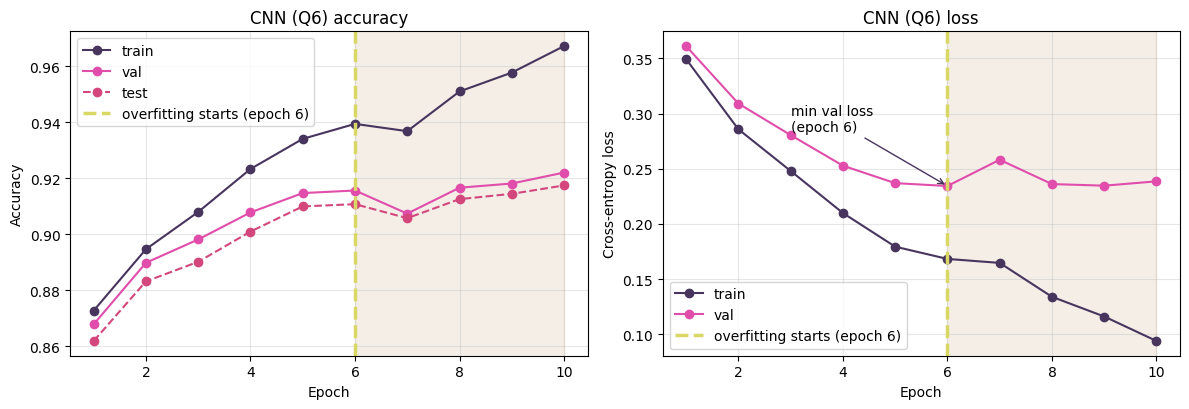

In [73]:
ep = range(1, len(hist_cnn['val_loss']) + 1)
best = int(np.argmin(hist_cnn['val_loss'])) + 1     # epoch with the lowest val loss (+1: epochs start at 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# accuracy
ax = axes[0]
ax.plot(ep, hist_cnn['train_acc'], color='#47355E', marker='o', label='train')
ax.plot(ep, hist_cnn['val_acc'],   color='#E04DAA', marker='o', label='val')
ax.plot(ep, hist_cnn['test_acc'],  color='#D3477D', marker='o', linestyle='--', label='test')
ax.set(title='CNN (Q6) accuracy', xlabel='Epoch', ylabel='Accuracy')

# validation loss
ax = axes[1]
ax.plot(ep, hist_cnn['train_loss'], color='#47355E', marker='o', label='train')
ax.plot(ep, hist_cnn['val_loss'],   color='#E04DAA', marker='o', label='val')
ax.set(title='CNN (Q6) loss', xlabel='Epoch', ylabel='Cross-entropy loss')
ax.annotate(f'min val loss\n(epoch {best})',
            xy=(best, hist_cnn['val_loss'][best - 1]),
            xytext=(best - 3, hist_cnn['val_loss'][best - 1] + 0.05),
            arrowprops=dict(arrowstyle='->', color='#47355E'))

# mark the overfitting point on both plots
for ax in axes:
    ax.axvline(best, color='#DAD865', linewidth=2.5, linestyle='--', label=f'overfitting starts (epoch {best})')
    ax.axvspan(best, max(ep), color='#E5D5C3', alpha=0.4)        # shade the overfitting region
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

The model begins to overfit after epoch 6.

### 3.7

*Retrain CNN on augmented data set and make a new model*

In [74]:
# Create new data loaders from data augmentation
train_loader_aug = make_loader(x_train_augExpand, y_train_augExpand, shuffle=True)

torch.manual_seed(2026) # reproducible between runs
# architecture hyperparameters tuned earlier: filters 32/64 and kernel size 3x3
model_cnn_aug = ConvNet(
    in_channels=1,       # grayscale input
    out_channels1=32,    # filters in conv layer 1
    out_channels2=64,    # filters in conv layer 2
    kernel_size=3,       # 3x3 filters
    stride=1,
    padding=1,           # keeps 28x28 through each conv
    fc_units=256,        # FC hidden layer (required by the assignment)
    n_classes=10,        # total number of classes (clothing item labels)
    I=28,                # input image width/height
    use_bn=False          # batch normalization
).to(device)

hist_cnn_aug = train_model(
    model_cnn_aug, train_loader_aug, val_loader, test_loader,
    epochs=10,
    lr=0.01,             # from lr sweep
    momentum=0.9,        # from momentum sweep (lr=0.01)
)


Starting training...
Training batches per epoch: 1500
Validation batches: 188
  Epoch 1, batch 100/1500, loss 1.2198
  Epoch 1, batch 200/1500, loss 0.6410
  Epoch 1, batch 300/1500, loss 0.5497
  Epoch 1, batch 400/1500, loss 0.5024
  Epoch 1, batch 500/1500, loss 0.4613
  Epoch 1, batch 600/1500, loss 0.4586
  Epoch 1, batch 700/1500, loss 0.4083
  Epoch 1, batch 800/1500, loss 0.4059
  Epoch 1, batch 900/1500, loss 0.3804
  Epoch 1, batch 1000/1500, loss 0.3930
  Epoch 1, batch 1100/1500, loss 0.3951
  Epoch 1, batch 1200/1500, loss 0.3853
  Epoch 1, batch 1300/1500, loss 0.3376
  Epoch 1, batch 1400/1500, loss 0.3494
  Epoch 1, batch 1500/1500, loss 0.3357
Epoch 1/10 | train loss 0.3674 acc 0.8665 | val loss 0.3584 acc 0.8742 | test acc 0.8660 | 6.5s
  Epoch 2, batch 100/1500, loss 0.3253
  Epoch 2, batch 200/1500, loss 0.3066
  Epoch 2, batch 300/1500, loss 0.3156
  Epoch 2, batch 400/1500, loss 0.3174
  Epoch 2, batch 500/1500, loss 0.3052
  Epoch 2, batch 600/1500, loss 0.3154
 

*Check results*

In [75]:
cnn_epochs_aug = epoch_table(hist_cnn_aug)
best = cnn_epochs_aug['val_acc'].idxmax()
print(f"Best validation accuracy at epoch {best} and is {cnn_epochs_aug['val_acc'].max()*100:.2f}%\n")
cnn_epochs_aug

Best validation accuracy at epoch 9 and is 92.54%



,train_loss,val_loss,train_acc,val_acc,test_acc,train-val gap,epoch_time
epoch,,,,,,,
1,0.3674,0.3584,0.8665,0.8742,0.8660,-0.0078,6.5274
2,0.2608,0.2671,0.9036,0.9004,0.8930,0.0032,6.5438
3,0.2092,0.2308,0.9250,0.9150,0.9123,0.0100,6.2256
4,0.1990,0.2561,0.9241,0.9118,0.9070,0.0123,5.9586
5,0.1509,0.2239,0.9450,0.9203,0.9168,0.0247,6.4295
6,0.1209,0.2218,0.9573,0.9237,0.9213,0.0336,6.1987
7,0.1132,0.2523,0.9572,0.9205,0.9159,0.0367,6.5279
8,0.0931,0.2465,0.9667,0.9204,0.9142,0.0463,7.1674
9,0.0751,0.2589,0.9726,0.9254,0.9172,0.0472,6.7140


In [76]:
# compare CNN clean vs data augmentation

q7_table = pd.DataFrame([
    summarize('CNN Q6 (clean)',             hist_cnn,     len(x_train)),
    summarize('CNN Q7 (clean + augmented)', hist_cnn_aug, len(x_train_augExpand)),
]).set_index('model').round(4)

q7_table

,train size,val acc (final),test acc (final),best val epoch,val acc (best),test acc (best),time / epoch (s)
model,,,,,,,
CNN Q6 (clean),48000,0.9220,0.9174,10,0.9220,0.9174,3.1824
CNN Q7 (clean + augmented),96000,0.9218,0.9188,9,0.9254,0.9172,6.5333


With data augmentation, the CNN reached higher best validation accuracy.

Each epoch took about twice as long because the training set doubled from 48k to 96k because I chose to expand it due to the advantage of data augmentation.

###Further Exploratory Analysis

*Try increasing variation in training data by augmenting new 48k training images each epoch, and concatenate them with the 48k clean images for the training dataset.*

In [77]:
from torch.utils.data import ConcatDataset

norm = transforms.Normalize((float(mean / 255),), (float(std / 255),))   # same stats as before, 0–1 scale

clean_tf = transforms.Compose([transforms.ToTensor(), norm])
aug_tf   = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    norm,
])

ds_clean = Subset(datasets.FashionMNIST(root='./data', train=True, download=True, transform=clean_tf), train_indices)
ds_aug   = Subset(datasets.FashionMNIST(root='./data', train=True, download=True, transform=aug_tf),   train_indices)

# 48k clean + 48k augmented, with a NEW random augmentation every epoch
train_loader_dyn = DataLoader(ConcatDataset([ds_clean, ds_aug]), batch_size=64, shuffle=True, num_workers=0)  # 0 = load in main process (safe in local Jupyter)

torch.manual_seed(2026) # reproducible between runs

# architecture hyperparameters tuned earlier: filters 32/64 and kernel size 3x3
model_cnn_dyn = ConvNet(
    in_channels=1,       # grayscale input
    out_channels1=32,    # filters in conv layer 1
    out_channels2=64,    # filters in conv layer 2
    kernel_size=3,       # 3x3 filters
    stride=1,
    padding=1,           # keeps 28x28 through each conv
    fc_units=256,        # FC hidden layer (required by the assignment)
    n_classes=10,        # total number of classes (clothing item labels)
    I=28,                # input image width/height
    use_bn=False          # batch normalization
).to(device)

hist_cnn_dyn = train_model(
    model_cnn_dyn, train_loader_dyn, val_loader, test_loader,
    epochs=10,
    lr=0.01,             # from lr sweep
    momentum=0.9,        # from momentum sweep (lr=0.01)
)

Starting training...
Training batches per epoch: 1500
Validation batches: 188
  Epoch 1, batch 100/1500, loss 1.2246
  Epoch 1, batch 200/1500, loss 0.6408
  Epoch 1, batch 300/1500, loss 0.5494
  Epoch 1, batch 400/1500, loss 0.5003
  Epoch 1, batch 500/1500, loss 0.4567
  Epoch 1, batch 600/1500, loss 0.4504
  Epoch 1, batch 700/1500, loss 0.3992
  Epoch 1, batch 800/1500, loss 0.4034
  Epoch 1, batch 900/1500, loss 0.3806
  Epoch 1, batch 1000/1500, loss 0.3920
  Epoch 1, batch 1100/1500, loss 0.3966
  Epoch 1, batch 1200/1500, loss 0.3903
  Epoch 1, batch 1300/1500, loss 0.3395
  Epoch 1, batch 1400/1500, loss 0.3469
  Epoch 1, batch 1500/1500, loss 0.3362
Epoch 1/10 | train loss 0.3567 acc 0.8701 | val loss 0.3482 acc 0.8772 | test acc 0.8685 | 13.7s
  Epoch 2, batch 100/1500, loss 0.3110
  Epoch 2, batch 200/1500, loss 0.3145
  Epoch 2, batch 300/1500, loss 0.3151
  Epoch 2, batch 400/1500, loss 0.3277
  Epoch 2, batch 500/1500, loss 0.2989
  Epoch 2, batch 600/1500, loss 0.2947


In [78]:
cnn_epochs_dyn = epoch_table(hist_cnn_dyn)
best = cnn_epochs_dyn['val_acc'].idxmax()
print(f"Best validation accuracy at epoch {best} and is {cnn_epochs_dyn['val_acc'].max()*100:.2f}%\n")
cnn_epochs_dyn

Best validation accuracy at epoch 9 and is 92.78%



,train_loss,val_loss,train_acc,val_acc,test_acc,train-val gap,epoch_time
epoch,,,,,,,
1,0.3567,0.3482,0.8701,0.8772,0.8685,-0.0072,13.7141
2,0.2814,0.2802,0.8976,0.9004,0.8919,-0.0029,15.0374
3,0.2264,0.2419,0.9175,0.9128,0.9078,0.0047,14.2203
4,0.1981,0.2360,0.9258,0.9155,0.9148,0.0103,12.3885
5,0.1823,0.2228,0.9343,0.9199,0.9172,0.0144,12.2797
6,0.1747,0.2301,0.9365,0.9198,0.9125,0.0167,14.5786
7,0.1482,0.2166,0.9464,0.9260,0.9189,0.0204,13.8436
8,0.1354,0.2291,0.9496,0.9211,0.9187,0.0285,16.2526
9,0.1273,0.2280,0.9530,0.9278,0.9233,0.0252,14.3101


In [79]:
# Compare all 3 versions: 1. Clean data, 2. Clean + augmentation, 3. Clean + dynamic augmentation
def summarize(name, hist, n_train):
    best = int(np.argmax(hist['val_acc']))              # epoch index chosen by validation
    return {'model': name,
            'train size': n_train,
            'val acc (final)':  hist['val_acc'][-1],
            'test acc (final)': hist['test_acc'][-1],
            'best val epoch':   best + 1,
            'val acc (best)':   hist['val_acc'][best],
            'test acc (best)':  hist['test_acc'][best],
            'time / epoch (s)': np.mean(hist['epoch_time'][1:])}   # skip epoch 1 warm-up

q7_table = pd.DataFrame([
    summarize('CNN Q6 (clean)',                        hist_cnn,     len(x_train)),
    summarize('CNN Q7 (clean + static aug)',           hist_cnn_aug, len(x_train_augExpand)),
    summarize('CNN Q7 (clean + fresh aug each epoch)', hist_cnn_dyn, len(train_loader_dyn.dataset)),
]).set_index('model').round(4)

q7_table

,train size,val acc (final),test acc (final),best val epoch,val acc (best),test acc (best),time / epoch (s)
model,,,,,,,
CNN Q6 (clean),48000,0.9220,0.9174,10,0.9220,0.9174,3.1824
CNN Q7 (clean + static aug),96000,0.9218,0.9188,9,0.9254,0.9172,6.5333
CNN Q7 (clean + fresh aug each epoch),96000,0.9182,0.9135,9,0.9278,0.9233,14.2052


Validation accuracy at the best epoch is highest for the CNN Q7 dynamic augmentation model. It's a decent improvement over the clean training dataset. It is about 2 times slower than the static augmentation though and 5 times slower than no augmentation.

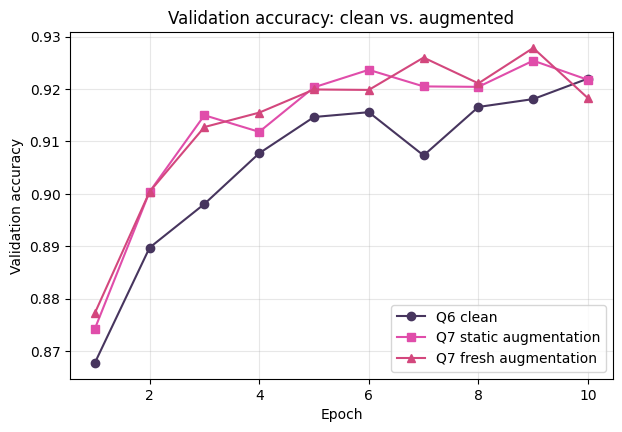

In [80]:
ep = range(1, 11)
plt.figure(figsize=(7, 4.5))
plt.plot(ep, hist_cnn['val_acc'],     color='#47355E', marker='o', label='Q6 clean')
plt.plot(ep, hist_cnn_aug['val_acc'], color='#E04DAA', marker='s', label='Q7 static augmentation')
plt.plot(ep, hist_cnn_dyn['val_acc'], color='#D3477D', marker='^', label='Q7 fresh augmentation')
plt.title('Validation accuracy: clean vs. augmented')
plt.xlabel('Epoch'); plt.ylabel('Validation accuracy')
plt.grid(alpha=0.3); plt.legend()
plt.show()

*Try moving transform augmentation to the GPU in the dynamic augmentation model*

### 3.8

In [ ]:
from torchvision.models import resnet50, ResNet50_Weights
from torch.utils.data import Subset, TensorDataset

weights = ResNet50_Weights.IMAGENET1K_V2
image_size = 224
batch_size_resnet = 64

# augmenetion as seen in 3.5
resnet_train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])
resnet_eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

train_resnet_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=resnet_train_transform)
train_resnet_eval_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=resnet_eval_transform)
test_resnet_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=resnet_eval_transform)

# seperate into training / validation set
train_resnet_set = Subset(train_resnet_dataset, train_indices)
val_resnet_set = Subset(train_resnet_eval_dataset, val_indices)

train_resnet_loader = DataLoader(train_resnet_set, batch_size=batch_size_resnet, shuffle=False, num_workers=0)
val_resnet_loader = DataLoader(val_resnet_set, batch_size=batch_size_resnet, shuffle=False, num_workers=0)
test_resnet_loader = DataLoader(test_resnet_dataset, batch_size=batch_size_resnet, shuffle=False, num_workers=0)

# Compute the frozen convolutional representation once.
resnet_backbone = resnet50(weights=weights).to(device)
for parameter in resnet_backbone.parameters():
    parameter.requires_grad = False
resnet_backbone.fc = nn.Identity()
resnet_backbone.eval()


def extract_resnet_features(model, loader):
    features, labels = [], []
    with torch.no_grad():
        for images, batch_labels in loader:
            features.append(model(images.to(device)).cpu())
            labels.append(batch_labels)
    return torch.cat(features), torch.cat(labels)

torch.manual_seed(2026)
feature_start = time.time()
train_features, train_feature_labels = extract_resnet_features(resnet_backbone, train_resnet_loader)
val_features, val_feature_labels = extract_resnet_features(resnet_backbone, val_resnet_loader)
test_features, test_feature_labels = extract_resnet_features(resnet_backbone, test_resnet_loader)
feature_time = time.time() - feature_start
print(f'Cached ResNet features in {feature_time:.1f}s | train features: {tuple(train_features.shape)}')

feature_train_loader = DataLoader(TensorDataset(train_features, train_feature_labels), batch_size=batch_size_resnet, shuffle=True)
feature_val_loader = DataLoader(TensorDataset(val_features, val_feature_labels), batch_size=batch_size_resnet, shuffle=False)
feature_test_loader = DataLoader(TensorDataset(test_features, test_feature_labels), batch_size=batch_size_resnet, shuffle=False)


def make_resnet_head(hidden_units):
    layers = []
    input_dim = 2048
    for units in hidden_units:
        layers.extend([nn.Linear(input_dim, units), nn.ReLU(), nn.Dropout(0.3)])
        input_dim = units
    layers.append(nn.Linear(input_dim, 10))
    return nn.Sequential(*layers).to(device)


def evaluate_head(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for features, labels in loader:
            features, labels = features.to(device), labels.to(device)
            outputs = model(features)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


def train_resnet_head(hidden_units, epochs=10, lr=0.001):
    model = make_resnet_head(hidden_units)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'test_loss': [], 'train_acc': [], 'val_acc': [], 'test_acc': [], 'epoch_time': []}
    total_start = time.time()

    for epoch in range(epochs):
        model.train()
        epoch_start = time.time()
        for features, labels in feature_train_loader:
            features, labels = features.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(features), labels)
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate_head(model, feature_train_loader, criterion)
        val_loss, val_acc = evaluate_head(model, feature_val_loader, criterion)
        test_loss, test_acc = evaluate_head(model, feature_test_loader, criterion)
        epoch_time = time.time() - epoch_start
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['test_acc'].append(test_acc)
        history['epoch_time'].append(epoch_time)
        print(f'Epoch {epoch + 1}/{epochs} | train acc {train_acc:.4f} | val acc {val_acc:.4f} | test acc {test_acc:.4f} | time {epoch_time:.1f}s')

    history['total_time'] = time.time() - total_start
    history['mean_epoch_time'] = np.mean(history['epoch_time'])
    print(f"Head training time: {history['total_time']:.1f}s ({history['mean_epoch_time']:.1f}s/epoch)")
    return model, history


head_configs = {'0 hidden layers': [], '1 hidden layer': [256], '2 hidden layers': [512, 256], '3 hidden layers': [512, 256, 128]}
resnet_histories = {}
resnet_rows = []
for name, hidden_units in head_configs.items():
    torch.manual_seed(2026)
    model_head, history_resnet = train_resnet_head(hidden_units)
    resnet_histories[name] = history_resnet
    best_epoch = int(np.argmax(history_resnet['val_acc']))
    resnet_rows.append({
        'model': name,
        'trainable parameters': sum(parameter.numel() for parameter in model_head.parameters()),
        'train accuracy at best epoch': history_resnet['train_acc'][best_epoch],
        'validation accuracy at best epoch': history_resnet['val_acc'][best_epoch],
        'test accuracy at best epoch': history_resnet['test_acc'][best_epoch],
        'mean epoch time (s)': history_resnet['mean_epoch_time'],
    })

resnet_results = pd.DataFrame(resnet_rows).sort_values('validation accuracy at best epoch', ascending=False).set_index('model')
resnet_results.round(4)

Cached ResNet features in 498.0s | train features: (48000, 2048)
Epoch 1/10 | train acc 0.8760 | val acc 0.8678 | test acc 0.8675 | time 2.1s
Epoch 2/10 | train acc 0.8941 | val acc 0.8817 | test acc 0.8808 | time 1.7s
Epoch 3/10 | train acc 0.9003 | val acc 0.8826 | test acc 0.8851 | time 1.6s
Epoch 4/10 | train acc 0.9101 | val acc 0.8880 | test acc 0.8877 | time 1.6s
Epoch 5/10 | train acc 0.9145 | val acc 0.8928 | test acc 0.8902 | time 1.6s
Epoch 6/10 | train acc 0.9165 | val acc 0.8886 | test acc 0.8875 | time 1.7s
Epoch 7/10 | train acc 0.9202 | val acc 0.8916 | test acc 0.8932 | time 1.7s
Epoch 8/10 | train acc 0.9210 | val acc 0.8904 | test acc 0.8897 | time 2.3s
Epoch 9/10 | train acc 0.9246 | val acc 0.8954 | test acc 0.8932 | time 2.0s
Epoch 10/10 | train acc 0.9285 | val acc 0.8938 | test acc 0.8930 | time 1.8s
Head training time: 18.1s (1.8s/epoch)
Epoch 1/10 | train acc 0.8964 | val acc 0.8724 | test acc 0.8732 | time 3.5s
Epoch 2/10 | train acc 0.9096 | val acc 0.8929 |

,trainable parameters,train accuracy at best epoch,validation accuracy at best epoch,test accuracy at best epoch,mean epoch time (s)
model,,,,,
2 hidden layers,1182986,0.9638,0.9052,0.9008,4.5139
3 hidden layers,1214602,0.9635,0.9048,0.9049,4.7635
1 hidden layer,527114,0.9686,0.9034,0.9017,3.1814
0 hidden layers,20490,0.9246,0.8954,0.8932,1.8104


*two hidden layers was the chosen number of fully-connected layers, due to highest validation accuracy, and a proven balance between speed / accuracy in training*

When doing the comparison, the mean epoch trianing time is very similiar with the Q5 model slightly faster at 1.97s in comparison to 2.00. In terms of accuracy, this is where the pre-trained model perfomaed better with a validation accuracy of 89.8% in comparison to 87.6%.

The CNN in part 7 has a better accuracy standing at about 92.6%, but a much longer training time taking 8.7s per epoch to train the model

### 3.9

In [82]:
# Food101 input for the existing ResNet feature and head-training functions.
food101_train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])
food101_eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

food101_train_dataset = datasets.Food101(root='./data', split='train', download=True, transform=food101_train_transform)
food101_train_eval_dataset = datasets.Food101(root='./data', split='train', download=True, transform=food101_eval_transform)
food101_test_dataset = datasets.Food101(root='./data', split='test', download=True, transform=food101_eval_transform)

food101_generator = torch.Generator().manual_seed(2026)
food101_indices = torch.randperm(len(food101_train_dataset), generator=food101_generator).tolist()
food101_train_size = int(0.8 * len(food101_indices))
food101_train_indices = food101_indices[:food101_train_size]
food101_val_indices = food101_indices[food101_train_size:]
torch.manual_seed(2026)
feature_train_loader = DataLoader(
    TensorDataset(*extract_resnet_features(
        resnet_backbone,
        DataLoader(Subset(food101_train_dataset, food101_train_indices), batch_size=batch_size_resnet, shuffle=False, num_workers=0),
    )),
    batch_size=batch_size_resnet,
    shuffle=True,
)
feature_val_loader = DataLoader(
    TensorDataset(*extract_resnet_features(
        resnet_backbone,
        DataLoader(Subset(food101_train_eval_dataset, food101_val_indices), batch_size=batch_size_resnet, shuffle=False, num_workers=0),
    )),
    batch_size=batch_size_resnet,
    shuffle=False,
)
feature_test_loader = DataLoader(
    TensorDataset(*extract_resnet_features(
        resnet_backbone,
        DataLoader(food101_test_dataset, batch_size=batch_size_resnet, shuffle=False, num_workers=0),
    )),
    batch_size=batch_size_resnet,
    shuffle=False,
)

# The existing training/evaluation functions are reused; Food101 needs 101 logits.
def make_resnet_head(hidden_units):
    layers = []
    input_dim = 2048
    for units in hidden_units:
        layers.extend([nn.Linear(input_dim, units), nn.ReLU(), nn.Dropout(0.3)])
        input_dim = units
    layers.append(nn.Linear(input_dim, 101))
    return nn.Sequential(*layers).to(device)

food101_resnet_histories = {}
food101_resnet_rows = []
for name, hidden_units in head_configs.items():
    torch.manual_seed(2026)
    model_head, history_food101 = train_resnet_head(hidden_units)
    food101_resnet_histories[name] = history_food101
    best_epoch = int(np.argmax(history_food101['val_acc']))
    food101_resnet_rows.append({
        'model': name,
        'trainable parameters': sum(parameter.numel() for parameter in model_head.parameters()),
        'train accuracy at best epoch': history_food101['train_acc'][best_epoch],
        'validation accuracy at best epoch': history_food101['val_acc'][best_epoch],
        'test accuracy at best epoch': history_food101['test_acc'][best_epoch],
        'mean epoch time (s)': history_food101['mean_epoch_time'],
    })

food101_resnet_results = pd.DataFrame(food101_resnet_rows).sort_values(
    'validation accuracy at best epoch', ascending=False
).set_index('model')
food101_resnet_results.round(4)

100%|██████████| 5.00G/5.00G [18:28<00:00, 4.51MB/s] 


Epoch 1/10 | train acc 0.5925 | val acc 0.5636 | test acc 0.6080 | time 3.5s
Epoch 2/10 | train acc 0.6574 | val acc 0.5998 | test acc 0.6441 | time 3.2s
Epoch 3/10 | train acc 0.6930 | val acc 0.6156 | test acc 0.6616 | time 3.1s
Epoch 4/10 | train acc 0.7185 | val acc 0.6234 | test acc 0.6694 | time 2.8s
Epoch 5/10 | train acc 0.7412 | val acc 0.6302 | test acc 0.6737 | time 2.8s
Epoch 6/10 | train acc 0.7607 | val acc 0.6331 | test acc 0.6756 | time 2.8s
Epoch 7/10 | train acc 0.7799 | val acc 0.6328 | test acc 0.6787 | time 2.7s
Epoch 8/10 | train acc 0.7956 | val acc 0.6319 | test acc 0.6772 | time 2.9s
Epoch 9/10 | train acc 0.8061 | val acc 0.6328 | test acc 0.6764 | time 2.7s
Epoch 10/10 | train acc 0.8187 | val acc 0.6320 | test acc 0.6781 | time 2.9s
Head training time: 29.4s (2.9s/epoch)
Epoch 1/10 | train acc 0.5761 | val acc 0.5523 | test acc 0.6027 | time 4.5s
Epoch 2/10 | train acc 0.6435 | val acc 0.5972 | test acc 0.6410 | time 4.0s
Epoch 3/10 | train acc 0.6823 | val 

,trainable parameters,train accuracy at best epoch,validation accuracy at best epoch,test accuracy at best epoch,mean epoch time (s)
model,,,,,
0 hidden layers,206949,0.7607,0.6331,0.6756,2.9411
1 hidden layer,550501,0.7759,0.6214,0.6677,4.3177
2 hidden layers,1206373,0.8196,0.6147,0.6612,6.4275
3 hidden layers,1226341,0.8034,0.5945,0.6431,6.0512


*Expected drop in accuracy, as Food-101 has 101 classes vs. the 10 in FashionMNIST.*

#### Food101 preprocessing differences from 3.8
Food101 images are already RGB, so there is no Grayscale conversion needed. Food101 has 101 classes rather than FashionMNIST's 10, so the final head outputs 101 logits. 

#### New

In [ ]:
from torchvision.models import resnet50, ResNet50_Weights
from torch.utils.data import Subset, TensorDataset

weights = ResNet50_Weights.IMAGENET1K_V2
image_size = 224
batch_size_resnet = 64
n_aug_epochs = 3

# augmenetion as seen in 3.5
resnet_train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])
resnet_eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

train_resnet_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=resnet_train_transform)
train_resnet_eval_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=resnet_eval_transform)
test_resnet_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=resnet_eval_transform)

# seperate into training / validation set
train_resnet_set = Subset(train_resnet_dataset, train_indices)
val_resnet_set = Subset(train_resnet_eval_dataset, val_indices)
train_clean_resnet_set = Subset(train_resnet_eval_dataset, train_indices)   # [NEW] clean training images (no augmentation)

train_resnet_loader = DataLoader(train_resnet_set, batch_size=batch_size_resnet, shuffle=False, num_workers=0)
val_resnet_loader = DataLoader(val_resnet_set, batch_size=batch_size_resnet, shuffle=False, num_workers=0)
test_resnet_loader = DataLoader(test_resnet_dataset, batch_size=batch_size_resnet, shuffle=False, num_workers=0)
train_clean_resnet_loader = DataLoader(train_clean_resnet_set, batch_size=batch_size_resnet, shuffle=False, num_workers=0)  # [NEW]

# Compute the frozen convolutional representation once.
resnet_backbone = resnet50(weights=weights).to(device)
for parameter in resnet_backbone.parameters():
    parameter.requires_grad = False
resnet_backbone.fc = nn.Identity()
resnet_backbone.eval()


def extract_resnet_features(model, loader):
    features, labels = [], []
    with torch.no_grad():
        for images, batch_labels in loader:
            features.append(model(images.to(device)).cpu())
            labels.append(batch_labels)
    return torch.cat(features), torch.cat(labels)

torch.manual_seed(2026)
feature_start = time.time()
clean_train_features, train_feature_labels = extract_resnet_features(resnet_backbone, train_clean_resnet_loader)  
val_features, val_feature_labels = extract_resnet_features(resnet_backbone, val_resnet_loader)
test_features, test_feature_labels = extract_resnet_features(resnet_backbone, test_resnet_loader)
feature_time = time.time() - feature_start

aug_start = time.time()                                                                       
aug_train_features = []                                                                       
for k in range(n_aug_epochs):                                                                 
    aug_feats, _ = extract_resnet_features(resnet_backbone, train_resnet_loader)              
    aug_train_features.append(aug_feats.half())                                               
aug_time_per_epoch = (time.time() - aug_start) / n_aug_epochs                                 
print(f'Clean/val/test features: {feature_time:.1f}s | augmented features: {aug_time_per_epoch:.1f}s per epoch')  


feature_val_loader = DataLoader(TensorDataset(val_features, val_feature_labels), batch_size=batch_size_resnet, shuffle=False)
feature_test_loader = DataLoader(TensorDataset(test_features, test_feature_labels), batch_size=batch_size_resnet, shuffle=False)


def make_epoch_train_loader(epoch):                                                           
    X = torch.cat([clean_train_features, aug_train_features[epoch % len(aug_train_features)].float()])  
    Y = torch.cat([train_feature_labels, train_feature_labels])                               
    return DataLoader(TensorDataset(X, Y), batch_size=batch_size_resnet, shuffle=True)        


def make_resnet_head(hidden_units):
    layers = []
    input_dim = 2048
    for units in hidden_units:
        layers.extend([nn.Linear(input_dim, units), nn.ReLU(), nn.Dropout(0.3)])
        input_dim = units
    layers.append(nn.Linear(input_dim, 10))
    return nn.Sequential(*layers).to(device)


def evaluate_head(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for features, labels in loader:
            features, labels = features.to(device), labels.to(device)
            outputs = model(features)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


def train_resnet_head(hidden_units, epochs=10, lr=0.001):
    model = make_resnet_head(hidden_units)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'test_loss': [], 'train_acc': [], 'val_acc': [], 'test_acc': [], 'epoch_time': []}
    total_start = time.time()

    for epoch in range(epochs):
        model.train()
        epoch_train_loader = make_epoch_train_loader(epoch)          
        epoch_start = time.time()
        for features, labels in epoch_train_loader:                  
            features, labels = features.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(features), labels)
            loss.backward()
            optimizer.step()
        epoch_time = time.time() - epoch_start                       

        train_loss, train_acc = evaluate_head(model, epoch_train_loader, criterion)   
        val_loss, val_acc = evaluate_head(model, feature_val_loader, criterion)
        test_loss, test_acc = evaluate_head(model, feature_test_loader, criterion)
       
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['test_loss'].append(test_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['test_acc'].append(test_acc)
        history['epoch_time'].append(epoch_time)
        print(f'Epoch {epoch + 1}/{epochs} | train acc {train_acc:.4f} | val acc {val_acc:.4f} | test acc {test_acc:.4f} | time {epoch_time:.1f}s')

    history['total_time'] = time.time() - total_start
    history['mean_epoch_time'] = np.mean(history['epoch_time'])
    print(f"Head training time: {history['total_time']:.1f}s ({history['mean_epoch_time']:.1f}s/epoch)")
    return model, history


head_configs = {'0 hidden layers': [], '1 hidden layer': [256], '2 hidden layers': [512, 256], '3 hidden layers': [512, 256, 128]}
resnet_histories = {}
resnet_rows = []
for name, hidden_units in head_configs.items():
    torch.manual_seed(2026)
    model_head, history_resnet = train_resnet_head(hidden_units)
    resnet_histories[name] = history_resnet
    best_epoch = int(np.argmax(history_resnet['val_acc']))
    resnet_rows.append({
        'model': name,
        'trainable parameters': sum(parameter.numel() for parameter in model_head.parameters()),
        'train accuracy at best epoch': history_resnet['train_acc'][best_epoch],
        'validation accuracy at best epoch': history_resnet['val_acc'][best_epoch],
        'test accuracy at best epoch': history_resnet['test_acc'][best_epoch],
        'mean epoch time (s)': history_resnet['mean_epoch_time'],
        'epoch time incl. augmentation (s)': history_resnet['mean_epoch_time'] + aug_time_per_epoch,   
    })



In [ ]:
resnet_results = pd.DataFrame(resnet_rows).sort_values('validation accuracy at best epoch', ascending=False).set_index('model')
resnet_results.round(4)

,trainable parameters,train accuracy at best epoch,validation accuracy at best epoch,test accuracy at best epoch,mean epoch time (s),epoch time incl. augmentation (s)
model,,,,,,
3 hidden layers,1214602,0.9521,0.9195,0.9134,6.2000,353.4220
1 hidden layer,527114,0.9561,0.9176,0.9120,4.1964,351.4185
2 hidden layers,1182986,0.9568,0.9173,0.9113,6.5269,353.7490
0 hidden layers,20490,0.9251,0.9079,0.9023,1.5302,348.7523


In [ ]:
# Food101 input for the existing ResNet feature and head-training functions.
food101_train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])
food101_eval_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

food101_train_dataset = datasets.Food101(root='./data', split='train', download=True, transform=food101_train_transform)
food101_train_eval_dataset = datasets.Food101(root='./data', split='train', download=True, transform=food101_eval_transform)
food101_test_dataset = datasets.Food101(root='./data', split='test', download=True, transform=food101_eval_transform)

food101_generator = torch.Generator().manual_seed(2026)
food101_indices = torch.randperm(len(food101_train_dataset), generator=food101_generator).tolist()
food101_train_size = int(0.8 * len(food101_indices))
food101_train_indices = food101_indices[:food101_train_size]
food101_val_indices = food101_indices[food101_train_size:]
torch.manual_seed(2026)


food101_clean_loader = DataLoader(Subset(food101_train_eval_dataset, food101_train_indices),        
                                  batch_size=batch_size_resnet, shuffle=False, num_workers=0)
food101_aug_loader = DataLoader(Subset(food101_train_dataset, food101_train_indices),               
                                batch_size=batch_size_resnet, shuffle=False, num_workers=0)

clean_train_features, train_feature_labels = extract_resnet_features(resnet_backbone, food101_clean_loader)  
aug_start = time.time()                                                                                      
aug_train_features = []                                                                                      
for k in range(n_aug_epochs):                                                                                
    aug_feats, _ = extract_resnet_features(resnet_backbone, food101_aug_loader)                              
    aug_train_features.append(aug_feats.half())                                                              
aug_time_per_epoch = (time.time() - aug_start) / n_aug_epochs                                                

feature_val_loader = DataLoader(
    TensorDataset(*extract_resnet_features(
        resnet_backbone,
        DataLoader(Subset(food101_train_eval_dataset, food101_val_indices), batch_size=batch_size_resnet, shuffle=False, num_workers=0),
    )),
    batch_size=batch_size_resnet,
    shuffle=False,
)
feature_test_loader = DataLoader(
    TensorDataset(*extract_resnet_features(
        resnet_backbone,
        DataLoader(food101_test_dataset, batch_size=batch_size_resnet, shuffle=False, num_workers=0),
    )),
    batch_size=batch_size_resnet,
    shuffle=False,
)

# The existing training/evaluation functions are reused; Food101 needs 101 logits.
def make_resnet_head(hidden_units):
    layers = []
    input_dim = 2048
    for units in hidden_units:
        layers.extend([nn.Linear(input_dim, units), nn.ReLU(), nn.Dropout(0.3)])
        input_dim = units
    layers.append(nn.Linear(input_dim, 101))
    return nn.Sequential(*layers).to(device)

food101_resnet_histories = {}
food101_resnet_rows = []
for name, hidden_units in head_configs.items():
    torch.manual_seed(2026)
    model_head, history_food101 = train_resnet_head(hidden_units)
    food101_resnet_histories[name] = history_food101
    best_epoch = int(np.argmax(history_food101['val_acc']))
    food101_resnet_rows.append({
        'model': name,
        'trainable parameters': sum(parameter.numel() for parameter in model_head.parameters()),
        'train accuracy at best epoch': history_food101['train_acc'][best_epoch],
        'validation accuracy at best epoch': history_food101['val_acc'][best_epoch],
        'test accuracy at best epoch': history_food101['test_acc'][best_epoch],
        'mean epoch time (s)': history_food101['mean_epoch_time'],
        'epoch time incl. augmentation (s)': history_food101['mean_epoch_time'] + aug_time_per_epoch,   
    })

food101_resnet_results = pd.DataFrame(food101_resnet_rows).sort_values(
    'validation accuracy at best epoch', ascending=False
).set_index('model')
food101_resnet_results.round(4)



Clean/val/test features: 473.3s | augmented features: 347.2s per epoch
Epoch 1/10 | train acc 0.8915 | val acc 0.8854 | test acc 0.8845 | time 2.4s
Epoch 2/10 | train acc 0.9039 | val acc 0.8956 | test acc 0.8950 | time 1.5s
Epoch 3/10 | train acc 0.9106 | val acc 0.9007 | test acc 0.8964 | time 1.3s
Epoch 4/10 | train acc 0.9147 | val acc 0.9046 | test acc 0.9020 | time 2.3s
Epoch 5/10 | train acc 0.9190 | val acc 0.9062 | test acc 0.9015 | time 1.6s
Epoch 6/10 | train acc 0.9195 | val acc 0.9067 | test acc 0.9006 | time 1.2s
Epoch 7/10 | train acc 0.9187 | val acc 0.9043 | test acc 0.8994 | time 1.3s
Epoch 8/10 | train acc 0.9232 | val acc 0.9048 | test acc 0.8975 | time 1.2s
Epoch 9/10 | train acc 0.9251 | val acc 0.9079 | test acc 0.9023 | time 1.2s
Epoch 10/10 | train acc 0.9226 | val acc 0.9052 | test acc 0.9012 | time 1.3s
Head training time: 38.5s (1.5s/epoch)
Epoch 1/10 | train acc 0.9086 | val acc 0.8994 | test acc 0.8943 | time 4.1s
Epoch 2/10 | train acc 0.9209 | val acc 0.

,trainable parameters,train accuracy at best epoch,validation accuracy at best epoch,test accuracy at best epoch,mean epoch time (s),epoch time incl. augmentation (s)
model,,,,,,
0 hidden layers,206949,0.7582,0.6553,0.6960,2.0706,512.3147
1 hidden layer,550501,0.8150,0.6424,0.6900,6.0770,516.3211
2 hidden layers,1206373,0.7736,0.6411,0.6846,8.6127,518.8568
3 hidden layers,1226341,0.8163,0.6300,0.6728,8.3846,518.6287


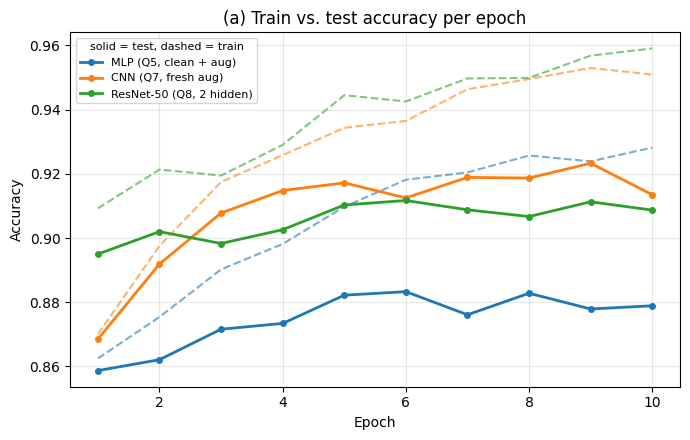

In [ ]:
# ---- Final comparison: all three models trained with augmentation ----
head = '2 hidden layers'                    
fig, ax = plt.subplots(figsize=(7, 4.5))

plot_curves({'MLP (Q5, clean + aug)':  (hist_mlp_aug['train'],          hist_mlp_aug['test']),
             'CNN (Q7, fresh aug)':    (hist_cnn_dyn['train_acc'],      hist_cnn_dyn['test_acc']),
             'ResNet-50 (Q8, 2 hidden)': (resnet_histories[head]['train_acc'],
                                          resnet_histories[head]['test_acc'])},
            '(a) Train vs. test accuracy per epoch', ax)


plt.tight_layout()
plt.show()

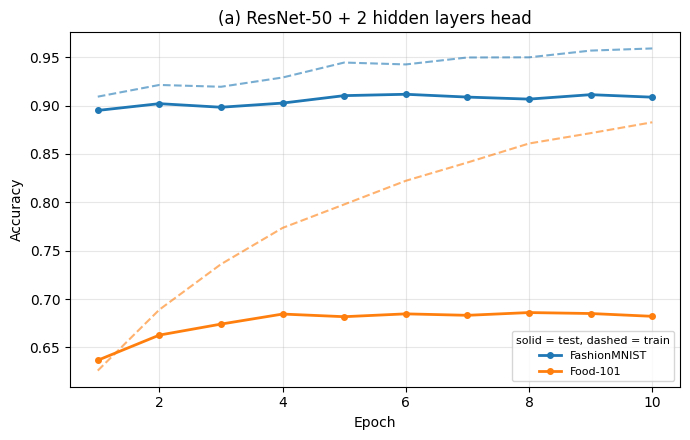

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))


plot_curves({'FashionMNIST': (resnet_histories[head]['train_acc'],         resnet_histories[head]['test_acc']),
             'Food-101':     (food101_resnet_histories[head]['train_acc'], food101_resnet_histories[head]['test_acc'])},
            f'(a) ResNet-50 + {head} head', ax)


plt.tight_layout()
plt.show()